# Transfer significance: does it exist, and which family is stronger?

Section **0.0** is the one-table headline (existence by relationship family, finished sets only); section **0** is the pooled summary (existence by relationship category across animals, and every category-vs-category pairing). Then five tables. **1** cross-architecture arms (another model size or family), **2** the Pythia seed families' existence tests, **3** the family comparisons, **4** the 160m re-pretraining direction matrix (dog, cat, lion, pig, chicken), **5** the OLMo-1B (DataDecide) cross-seed and cross-recipe (dolma / dclm / c4) arms. Every test reads a student against its OWN matched traitless control (the untuned sender base's numbers pool distilled into the same receiver on the same cells), student finetune seed 1, the 10 k-band teachers of each animal where the arm is a k-band arm (elephant, or a pilot-selected teacher set, in the OLMo arms). In tables 1, 2, 4 and 5 animals are never pooled into one stratum; table 3 adds one `dog+cat+lion+pig stratified` line per comparison, whose strata are (animal, cell) pairs.

**Only a finished set gets a p**: every listed teacher with a seed-1 endpoint on every design cell and a matched control on every design cell. An arm short of that, an arm with no controls, or a single-cell pilot is ONE amber row with a `⚠` status naming what is lacking (no p, `cells` = matched/design), never a test on the cells that happened to finish; teacher sets chosen on a pilot cell are read on every design cell, that pilot cell included — a pilot cell outside the design is simply not in the design. Section **6** rolls every such arm up into one table.

## 0.0 Headline: existence by family

- **Finished sets only**: every listed teacher with a seed-1 test endpoint on every design cell of the arm AND a matched control on every cell; an arm short of that is dropped, counted in `arms used` (finished/listed) and named in `note`.
- **Yardstick per arm** = its OWN matched control: `exceed.` = treatment runs above the arm's control maximum; `perm p` = stratified exceedance permutation (20 000 draws, seed 0, cells as strata, arms as an extra stratum, each against its own control maximum).
- **dominant** = the family's main animal (dog for Pythia-receiver families, elephant for the OLMo cross-seed / cross-recipe families); **stratified** (grey; only where ≥ 2 animals carry a finished arm) = every finished (animal, arm) block as its own stratum — the existence pooling, NOT §3's family-comparison unit (there an arm seen in several animals is ONE unit).
- **prior** = the receiver's test prior (`student_tree_prior`); `min / median / max` when the row spans receivers.
- **×prior** block = mean / median / p75 / p95 / max of the per-run `p(animal) / receiver test prior`, computed PER ARM, shown as `min / median / max` across the row's arms.
- **×control** block = the same five on the per-run `p_student / p_control` at the same cell; a control ≈ 0 blows the ratio up — read it next to the ×prior block.
- The OLMo dolma / dclm recipes share the seed-default init byte-for-byte, hence `same init, different corpus`; the §2/§3 `cross-seed` family = the full seeds = different init AND different data order.
- Highlighted = perm p < 0.05; the strip figure under the table draws each family's whole relabelling null (grey, in % of the row's runs) with its 95th percentile dashed and the observed exceedance count as the coloured line, the same numbers as the `exceed.` / `null 95th` columns.

In [1]:
import json
from subliminal_learning.analysis import transfer_headline as th
from subliminal_learning.analysis.setup import bootstrap

REPO, OUTPUT_ROOT = bootstrap()     # repo-anchored: every path below is absolute
ANIMALS = ["dog", "cat", "lion", "pig"]
TEACHERS = {a: json.loads((REPO / f"run_logs/registry/{a}_top10_kband_configs.json").read_text())["param_tags"] for a in ANIMALS}
FAMILIES = th.headline_families(REPO, TEACHERS)
HEADLINE = th.headline_table(FAMILIES, n_perm=20000)
th.style_headline_table(HEADLINE)

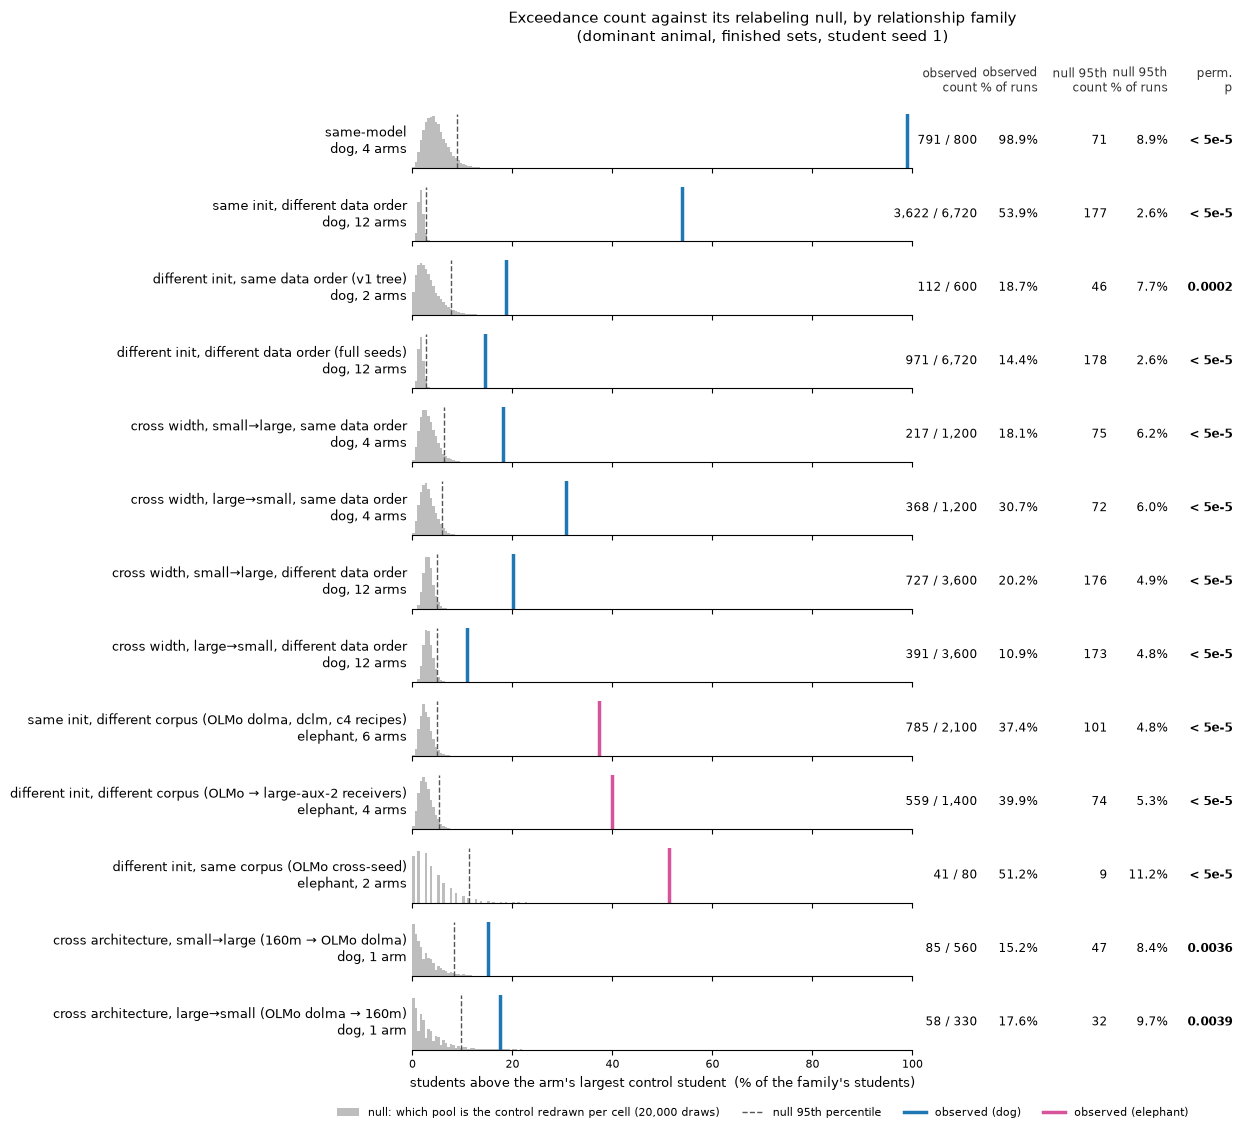

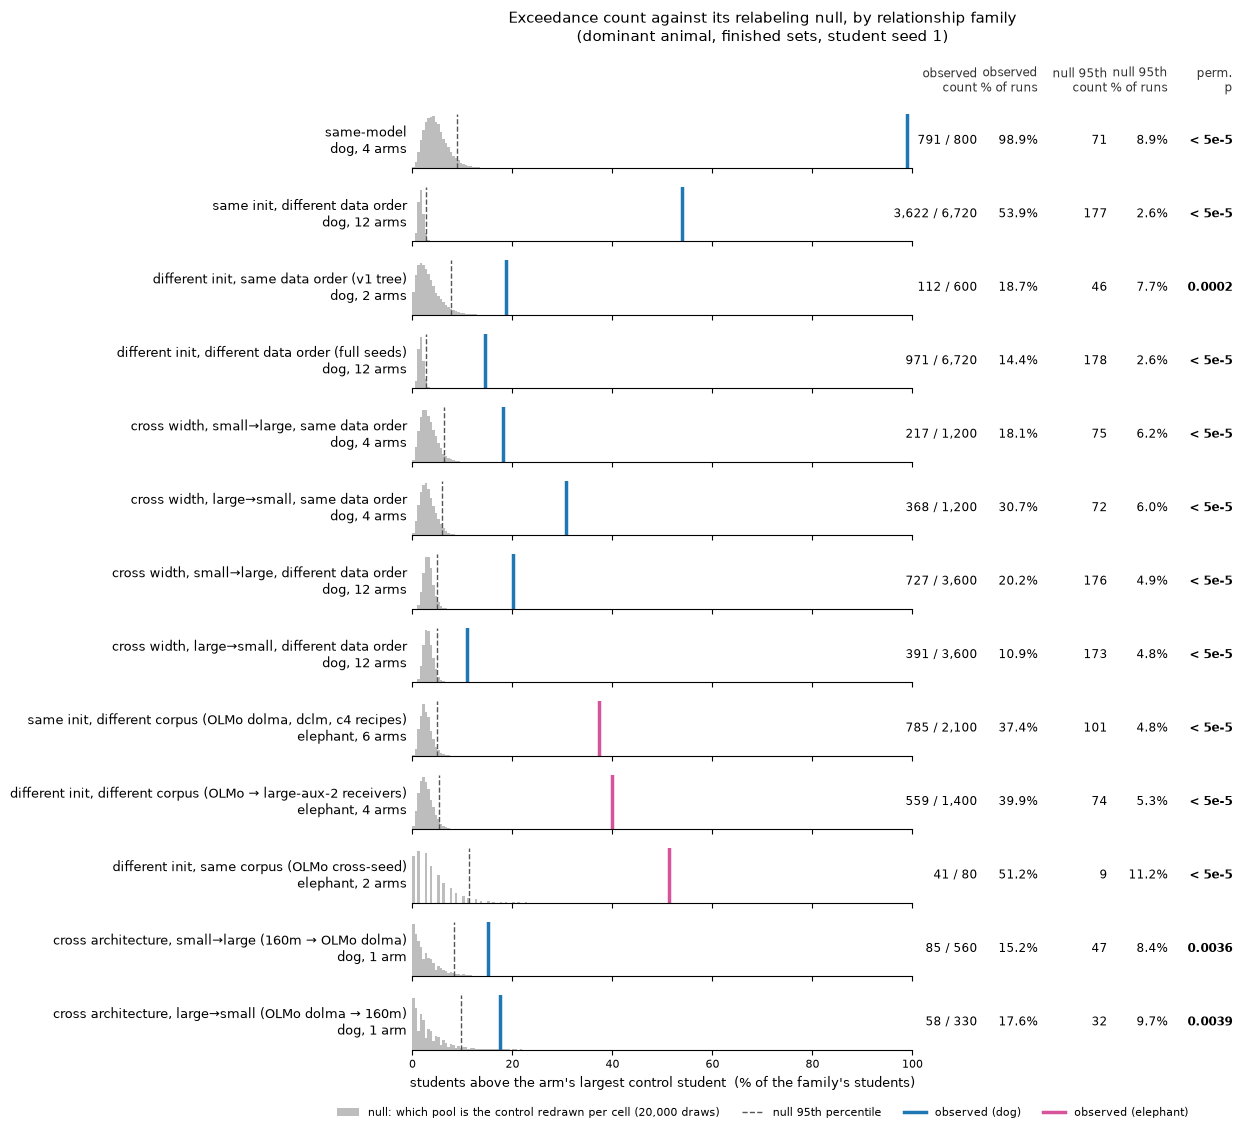

In [2]:
FIG = th.null_strip_figure(FAMILIES)
FIG.savefig(REPO / "notebooks/figures/transfer_null_strip.png", dpi=150, bbox_inches="tight")
FIG

## 0. Pooled summary

### 0a. Does transfer exist, by relationship of sender and receiver?

One pooled row per (relationship category, animal): every ordered 160m arm of the category (`analysis.transfer_matrix.relationship_category`, both directions pooled — self, same-model ws siblings, cross-data-order / same init, cross-init / same order split by code tree (v1.0 tree = the `wc1 ↔ wc2` weightc reruns on the v1.0 gpt-neox tree; modern tree = `pr1234 ↔ pr3` and `dclm1 ↔ dclm1234`), same init / different corpus, same init / different tree, cross-init + cross-order, and the two cross-width 160m↔410m rows) is judged against ITS OWN matched-control maximum, under the within-cell control-relabelling null, with arms as strata (`stats.transfer_significance_tests.stratified_exceedance_permutation`, 20 000 draws, seed 0, floor 5e-5); `exceed.` = treatment runs above their arm's control maximum out of `runs`, `arms p<0.05` = arms whose own per-arm p clears 0.05. The design is **core30** for every animal (partial arms included, scored on the core30 runs they have), so rows are comparable across animals; of the self row's seven diagonals only `orig` and the three full seeds carry core30 controls (`run_logs/campaigns/sl_samemodel_controls_core30_20260921`), the three `ds` diagonals none or part of focus20 only. Dog is the only animal with the different-corpus (`dclm`), modern-tree cross-init (`pr` and `dclm` pairs) and cross-width categories; the v1.0-tree cross-init / same-order category (`wc` siblings) exists in every animal, and cat also carries the same-init / different-tree (`pr1234 ↔ orig`) pair; the rest of cat, lion and pig is the seed families (their cross-data-order category is the three `orig → ds_i` arms — no ds-sender students). A category with no arm in an animal is not listed; `no controls` = every arm of the category is untestable (not a null result). Highlighted = perm p < 0.05.

In [3]:
import json, pandas as pd
from subliminal_learning.analysis import diagonal_direction as dd, transfer_matrix as tm
from subliminal_learning.analysis.setup import bootstrap

REPO, OUTPUT_ROOT = bootstrap()     # repo-anchored: every path below is absolute
ANIMALS = ["dog", "cat", "lion", "pig"]
TEACHERS = {a: json.loads((REPO / f"run_logs/registry/{a}_top10_kband_configs.json").read_text())["param_tags"] for a in ANIMALS}
CORE30 = dd.resolve_cells(REPO / "run_logs/registry/core30_cells.json")
EXIST = tm.relationship_existence_by_animal(ANIMALS, TEACHERS, CORE30, xarch_json=REPO / "run_logs/campaigns/xarch/xarch_significance_arms.json", n_perm=20000)
tm.style_relationship_existence_table(EXIST)

pile_probe cache: 1500 rows of 105210 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1200 rows of 105210 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)
pile_probe cache: 600 rows of 105210 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 900 rows of 105210 cached (0 added, 0 refreshed, 300 inventory paths without a record, 0 unreadable/kept)
pile_probe cache: 1200 rows of 105210 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1200 rows of 105210 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 3581 rows of 105210 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)
pile_probe cache: 300 rows of 105210 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)
pile_probe cache: 899 rows of 105210 cached (0 added, 0 refreshed, 1 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1114 rows of 105210 cached (0 added, 0 refreshed, 86 inventory paths without a record, 0 unreadable/kept)
pile_probe cache: 1200 rows of 105210 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1200 rows of 105210 cached (0 added, 0 refreshed, 204 inventory paths without a record, 0 unreadable/kept)
pile_probe cache: 1500 rows of 105210 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 900 rows of 105210 cached (0 added, 0 refreshed, 300 inventory paths without a record, 0 unreadable/kept)


### 0b. Which relationship transfers more? All category pairings (dog)

Each row asks whether category **A**'s SET of arms transfers more than **B**'s: the unit relabelled under the null is the ARM (the model pair), the stratum is (animal, cell), and the statistics — per-stratum mean contrast, per-stratum win probability (stratified Mann-Whitney), and the arm-level exceedance-fraction contrast — are read on the runs inside their stratum (`compare_families`, §3 legend). **Relative** value mode only (gap over the receiver's prior): receivers differ in prior across categories, so absolute gaps are not comparable. Pairings are every unordered pair of the seven 160m categories that carry controls (the cross-init / same-order category is split by code tree: v1.0 `wc1 ↔ wc2` vs modern `pr1234 ↔ pr3`, `dclm1 ↔ dclm1234`), oriented FOR DISPLAY so A is the category with the larger pooled exceedance fraction in 0a (an orientation picked from the data, which is exactly why the p's below are two-sided: those do not move when the two sides are swapped); the cross-width rows are excluded (a different receiver width and per-arm teacher sets), and the ws siblings have no controls. Every pairing, the ones with the self category included, is read on **core30**: the `orig` and full-seed diagonals now carry core30 controls, and the full-coverage rule drops the `ds` diagonals, which carry none (listed under the table). The three pairings that exist in every animal get a `dog+cat+lion+pig stratified` row beneath the dog row. Arm counts overstate independence (arms share senders and receivers), and the new categories carry 2–5 arms each, so their p's are coarse: with 2 vs 2 arms the floor is 1/6, with 2 vs 5 it is 1/21, with 5 vs 12 it is 1/6188 (exact enumeration up to 1e6 labelings, else 20 000 Monte-Carlo draws, floor 5e-5). Every p is TWO-SIDED by tail doubling — `p = min(1, 2 · min(P(null ≥ observed), P(null ≤ observed)))` — because which category is the stronger one was not fixed before the data; the DIRECTION is read off the sign of the contrast beside it (mean contrast vs 0, win prob. vs ½, exceedance-fraction contrast vs 0). Green = p < 0.05. **one-sided A>B** is the upper tail alone (`P(null ≥ observed)`), shown for reference and never highlighted.

- **arms A** / **arms B** — the model pairs (`sender→receiver`, short labels) whose runs enter each side of the line, in the order they enter the relabelling; on a `dog+cat+lion+pig stratified` row an arm seen in several animals is listed once (it is one unit of the relabelling). A side whose arms are every ordered pair of its models collapses to `all k directions among {…}`; a side whose arms share one sender (resp. receiver) to `x → {…}` (resp. `{…} → x`); anything partial stays an explicit list.
- **one-sided A>B (mean / win / exc.)** — the three one-sided upper-tail p's for A > B (mean contrast / win probability / exceedance), from the same null as the two-sided columns; `—` where a test is missing.
- **animals sig. A>B / B>A (mean / win / exc.)** — on a stratified row, `k/n` per statistic: k animals whose own relative-mode test is TWO-SIDED significant at p < 0.05 and whose contrast points that way by its sign, out of n animals carrying a usable comparison for that test; `—` on single-animal rows.
- **missing blocks** — the (animal, arm) blocks kept out by the coverage rule are no longer a column; the rows with any are listed under the table.

In [4]:
from IPython.display import Markdown, display

RUNS30, ARMS30, _ = tm.load_relationship_runs("dog", TEACHERS["dog"], CORE30)
ARM_TAB = tm.relationship_arm_table(RUNS30, tm.arm_coverage(RUNS30, TEACHERS["dog"], CORE30, CORE30), cells30=CORE30, on_disk=ARMS30)
PAIRS = tm.category_pairings(EXIST[EXIST.animal == "dog"].set_index("category").exceed_frac.to_dict())
PAIRINGS, PAIRING_NOTES = tm.relationship_pairing_table(PAIRS, tm.category_family_arms(ARM_TAB), TEACHERS, n_perm=20000,
                                                        cells_for=lambda a, b: ("core30", CORE30))
display(tm.style_relationship_pairing_table(PAIRINGS))
if PAIRING_NOTES:
    display(Markdown("**Blocks kept out by the coverage rule**\n" + "\n".join(
        f"- **{c} · {d} · {a}** — {text}" for (c, d, a), text in PAIRING_NOTES.items())))

**Blocks kept out by the coverage rule**
- **self (x→x) vs cross-data-order, same init · core30 · dog+cat+lion+pig stratified** — 39: cat ds1->ds1, cat ds2->ds2, cat ds3->ds3, cat wc1->wc1, cat wc2->wc2, cat pr1234->pr1234, cat dclm1234->dclm1234, cat ds2->orig, cat ds2->ds1, cat ds2->ds3, cat ds3->orig, cat ds3->ds1, cat ds3->ds2, lion ds1->ds1, lion ds2->ds2, lion ds3->ds3, lion wc1->wc1, lion wc2->wc2, lion pr1234->pr1234, lion dclm1234->dclm1234, lion ds2->orig, lion ds2->ds1, lion ds2->ds3, lion ds3->orig, lion ds3->ds1, lion ds3->ds2, pig ds1->ds1, pig ds2->ds2, pig ds3->ds3, pig wc1->wc1, pig wc2->wc2, pig pr1234->pr1234, pig dclm1234->dclm1234, pig ds2->orig, pig ds2->ds1, pig ds2->ds3, pig ds3->orig, pig ds3->ds1, pig ds3->ds2
- **self (x→x) vs cross-init + cross-data-order · core30 · dog+cat+lion+pig stratified** — 21: cat ds1->ds1, cat ds2->ds2, cat ds3->ds3, cat wc1->wc1, cat wc2->wc2, cat pr1234->pr1234, cat dclm1234->dclm1234, lion ds1->ds1, lion ds2->ds2, lion ds3->ds3, lion wc1->wc1, lion wc2->wc2, lion pr1234->pr1234, lion dclm1234->dclm1234, pig ds1->ds1, pig ds2->ds2, pig ds3->ds3, pig wc1->wc1, pig wc2->wc2, pig pr1234->pr1234, pig dclm1234->dclm1234
- **cross-data-order, same init vs cross-init + cross-data-order · core30 · dog+cat+lion+pig stratified** — 18: cat ds2->orig, cat ds2->ds1, cat ds2->ds3, cat ds3->orig, cat ds3->ds1, cat ds3->ds2, lion ds2->orig, lion ds2->ds1, lion ds2->ds3, lion ds3->orig, lion ds3->ds1, lion ds3->ds2, pig ds2->orig, pig ds2->ds1, pig ds2->ds3, pig ds3->orig, pig ds3->ds1, pig ds3->ds2

## 1. Cross-architecture transfer vs matched control

Does a teacher's numbers pool move a receiver of ANOTHER size or family above its matched control?

Each arm distils a teacher's numbers pool into a receiver of another size or family and compares it with the matched traitless control (the untuned sender base's pool distilled into the same receiver on the same cells), student seed 1, full-set teachers only (on-disk teachers an arm lists nowhere -- 4-cell screening fan-outs, other arms' teachers on the same tree -- are strays, auto-excluded and named in the status column); `-seed1` arms (different pretraining data order) are never pooled with same-order arms. Removing dead cells changed no p, so dead-excluded variants are omitted. There is ONE arm per (sender, receiver) pair: where part of a pair's teachers was pilot-selected, the pilot cells are scored like every other design cell — no pilot cell is held out anywhere (how each set was chosen is printed under the table). The `160m → 410m` and `160m → 410m-seed1` arms are the 09-20 promotions of the single-cell pilot `ep20_lr9e-5_r8a32` (a cell outside core30, so it is not a design cell at all): the top-10 senders per receiver by pilot ratio on core30 (`run_logs/campaigns/xarch_160m_410m_core30_tf32_20260920`, drained 09-21), where the fp32-complete senders and every control are fp32 and the promoted remainder tf32 (precision is a nuisance variable on those rows). The two reverse arms, `410m → 160m` and `410m-seed1 → 160m`, carry ten senders each (`run_logs/registry/p410m_top10_senders_pythia-410m{,-seed1}.json`): the two pre-existing core30 senders of the 09-16 arm plus eight chosen by pilot ratio (student p_target / its matched control) at `ep20_lr9e-5_r8a32` out of the ΔCE-stratified 410m teacher lattice (`run_logs/campaigns/p410m_teacher_strat_20260921` → `p410m_strat_to_160m_20260921` → `p410m_strat_core30_20260921`, drained 09-22); the pilot cell is outside core30, so both arms are read on all 30 cells and every remaining lattice teacher is a stray. These rows are fp32 throughout. The one nuisance is the pool size of a single seed1 sender: `ep2_lr5e-4_r32a64`'s numbers pool was generated at 125k, so the registry's `teacher_dataset_tags` reads that ONE sender under `ex10-20_prefix_n125k` while its nine siblings and the control tree stay at `n100k` (the seed1 manifest's eleventh candidate, `ep5_lr1e-3_r8a4`, was undistillable — 9 887 usable sequences — and never trained). `410m-seed1 → 160m` is now ONE arm for the pair; the separate single-teacher `r8a16` arm (same core30 design) is retired.

- **arm** — sender → receiver (animal), shown once per block: each arm's block opens with its pooled stratified-permutation row (`all full-set teachers`, grey), then one row per teacher; `POOLED` rows stack arms, each against its own control maximum.
- **teacher** — `all full-set teachers` on the arm's pooled row (grey, first in the block), else the teacher tag.
- **test** — the statistic that produced the row's p: the per-teacher sign test, or the stratified permutation (pooled over the arm's teachers, or across arms).
- **prior** — the receiver's test base p(animal), the unit of every ×prior column; blank on rows spanning receivers.
- **cells** — (treatment, control) cell pairs with values.
- **wins / n** — cells where treatment > control, over non-tied pairs.
- **sign p** — per-teacher sign test, wins ~ Binomial(n, ½), one-sided; descriptive, exact per cell.
- **exceed.** — descriptive count of treatment cells above the control's maximum cell, on the same cells as **cells**; no p, because values at different cells are not exchangeable.
- **perm p** — PRIMARY p: stratified within-cell exceedance permutation (20,000), pooled rows only.
- **treat / ctrl median ×prior** — median p(animal) over cells, in units of the receiver's test base prior.
- **treat / ctrl max ×prior** — the largest cell's p(animal), same cells and units as the medians.
- **dead (treat/ctrl)** — runs whose Pile/Dolma probe ΔCE exceeds the receiver's dead cut.
- **status** — empty on a tested arm; `⚠ …` on an arm lacking data (in progress, not started, no matched controls, single-cell pilot), whose one row is shaded amber and carries the reason in **test** and matched/design in **cells**.

Highlighted = perm p < 0.05 (the primary test); amber = no p.

In [5]:
from IPython.display import Markdown, display
from subliminal_learning.analysis.setup import bootstrap
from subliminal_learning.analysis.transfer_significance_io import significance_table, style_significance_table, registry_selection_notes

REPO, OUTPUT_ROOT = bootstrap()     # repo-anchored: every path below is absolute
XARCH = significance_table(REPO / "run_logs/campaigns/xarch/xarch_significance_arms.json")
style_significance_table(XARCH)

How the pilot-selected teacher sets of the table were chosen (from the registry's `selection_note`s):

In [6]:
display(Markdown(registry_selection_notes(REPO / "run_logs/campaigns/xarch/xarch_significance_arms.json")))

- **160m → 410m (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **410m → 160m (dog)** — the 10 senders are the manifest's param_tags (run_logs/registry/p410m_top10_senders_pythia-410m.json, selection: "2 pre-existing core30 senders (09-16 xarch) + top-7 of the ep20_lr9e-5_r8a32 pilot ratio + 1 phase-B pick"): the 2 pre-existing core30 senders of the 09-16 xarch arm plus the 8 pilot-selected ones, ranked by pilot ratio (student p_target / its matched control) on the single cell ep20_lr9e-5_r8a32 (run_logs/campaigns/p410m_strat_to_160m_20260921) — NOT a core30 cell, so no design cell is excluded. The pilot candidates were the ΔCE-stratified 410m teacher lattice (run_logs/campaigns/p410m_teacher_strat_20260921 → run_logs/campaigns/p410m_strat_to_160m_20260921 → run_logs/campaigns/p410m_strat_core30_20260921). Precision is fp32 throughout (teachers, students and controls).
- **410m → 160m-seed1 (dog)** — the 10 senders are the manifest's param_tags (run_logs/registry/p410m_top10_senders_pythia-410m.json, selection: "2 pre-existing core30 senders (09-16 xarch) + top-7 of the ep20_lr9e-5_r8a32 pilot ratio + 1 phase-B pick"): the 2 pre-existing core30 senders of the 09-16 xarch arm plus the 8 pilot-selected ones, ranked by pilot ratio (student p_target / its matched control) on the single cell ep20_lr9e-5_r8a32 (run_logs/campaigns/p410m_strat_to_160m_20260921) — NOT a core30 cell, so no design cell is excluded. The pilot candidates were the ΔCE-stratified 410m teacher lattice (run_logs/campaigns/p410m_teacher_strat_20260921 → run_logs/campaigns/p410m_strat_to_160m_20260921 → run_logs/campaigns/p410m_strat_core30_20260921). Precision is fp32 throughout (teachers, students and controls).
- **410m-seed1 → 160m (dog)** — the 10 senders are the manifest's param_tags (run_logs/registry/p410m_top10_senders_pythia-410m-seed1.json, selection: "2 pre-existing core30 senders (09-16 xarch) + top-7 of the ep20_lr9e-5_r8a32 pilot ratio + 1 phase-B pick"): the 2 pre-existing core30 senders of the 09-16 xarch arm plus the 8 pilot-selected ones, ranked by pilot ratio (student p_target / its matched control) on the single cell ep20_lr9e-5_r8a32 (run_logs/campaigns/p410m_strat_to_160m_20260921) — NOT a core30 cell, so no design cell is excluded. The pilot candidates were the ΔCE-stratified 410m teacher lattice (run_logs/campaigns/p410m_teacher_strat_20260921 → run_logs/campaigns/p410m_strat_to_160m_20260921 → run_logs/campaigns/p410m_strat_core30_20260921). Precision is fp32 throughout (teachers, students and controls).
- **160m → OLMo-1B (dog), core35** — ONE arm for the 160m → OLMo-1B pair: the 16 teachers full on core35 pool the legacy ep20_lr1e-4_r16a32 arm, the canonical top-10 tf32 fill and the pilot top-10 (top-10 by dog p_target of the tf32 pilot on the single core35 cell ep10_lr1e-4_r64a256, run_logs/campaigns/xolmo_pilottop10_core30_tf32_20260920/top10.tsv). That pilot cell is a core35 cell and is scored like every other design cell (no pilot-cell hold-out anywhere); the 4 canonical teachers still short of core35 are strays and auto-excluded. fp32/tf32 is a nuisance variable (the legacy teacher and the canonical pilot cells are fp32, the rest tf32).
- **OLMo-1B → 160m (dog), core30** — ONE arm for the OLMo-1B → 160m dog pair: the 11 teachers full on core30 pool the legacy ep10_lr3e-4_r64a128 arm and the top-10 of the 24-teacher dCE-stratified draw on the 2-cell pilot run_logs/campaigns/olmo_to_pythia_dogdraw24_2cells_20260919 (cells ep20_lr2e-4_r8a4, ranked on, and ep20_lr4e-4_r32a4; run_logs/campaigns/olmo_to_pythia_top10_core30_20260919/teachers.txt). Both pilot cells are core30 cells and are scored like every other design cell: teachers pilot-selected on a design cell are read on the whole design (no pilot-cell hold-out anywhere).
- **160m → 410m-seed1 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **160m → 410m-seed3 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **160m-seed1 → 410m-seed3 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **160m-seed3 → 410m-seed3 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **160m → 410m-seed2 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **160m-seed1 → 410m-seed1 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **160m-seed1 → 410m-seed2 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **160m-seed2 → 410m-seed2 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **160m-seed3 → 410m-seed2 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **410m-seed1 → 160m-seed1 (dog)** — the 10 senders are the manifest's param_tags (run_logs/registry/p410m_top10_senders_pythia-410m-seed1.json, selection: "2 pre-existing core30 senders (09-16 xarch) + top-7 of the ep20_lr9e-5_r8a32 pilot ratio + 1 phase-B pick"): the 2 pre-existing core30 senders of the 09-16 xarch arm plus the 8 pilot-selected ones, ranked by pilot ratio (student p_target / its matched control) on the single cell ep20_lr9e-5_r8a32 (run_logs/campaigns/p410m_strat_to_160m_20260921) — NOT a core30 cell, so no design cell is excluded. The pilot candidates were the ΔCE-stratified 410m teacher lattice (run_logs/campaigns/p410m_teacher_strat_20260921 → run_logs/campaigns/p410m_strat_to_160m_20260921 → run_logs/campaigns/p410m_strat_core30_20260921). Precision is fp32 throughout (teachers, students and controls).
- **410m-seed2 → 160m-seed2 (dog)** — the 10 senders are the campaign's TAGS (run_logs/campaigns/x410m_seed23_cross_20261007/make_jobs.py): the pythia-410m-seed2/-seed3 dog teachers (tseed 1) passing validation p_target >= 0.95 and pp1 Pile delta_ce <= 3.0 on BOTH bases, minus ep5_lr1e-4_r16a128 (dropped by hand) -- a gate, not a pilot ratio, so no cell entered the selection. pythia-160m-seed2 shares the PolyPythias seed-2 data order with pythia-410m-seed2. Precision: students and controls fp32, teacher numgen TF32; endpoint-only checkpoints.
- **410m-seed2 → 160m (dog)** — the 10 senders are the campaign's TAGS (run_logs/campaigns/x410m_seed23_cross_20261007/make_jobs.py): the pythia-410m-seed2/-seed3 dog teachers (tseed 1) passing validation p_target >= 0.95 and pp1 Pile delta_ce <= 3.0 on BOTH bases, minus ep5_lr1e-4_r16a128 (dropped by hand) -- a gate, not a pilot ratio, so no cell entered the selection. Different pretraining data order from pythia-410m-seed2. Precision: students and controls fp32, teacher numgen TF32; endpoint-only checkpoints.
- **410m-seed2 → 160m-seed1 (dog)** — the 10 senders are the campaign's TAGS (run_logs/campaigns/x410m_seed23_cross_20261007/make_jobs.py): the pythia-410m-seed2/-seed3 dog teachers (tseed 1) passing validation p_target >= 0.95 and pp1 Pile delta_ce <= 3.0 on BOTH bases, minus ep5_lr1e-4_r16a128 (dropped by hand) -- a gate, not a pilot ratio, so no cell entered the selection. Different pretraining data order from pythia-410m-seed2. Precision: students and controls fp32, teacher numgen TF32; endpoint-only checkpoints.
- **410m-seed2 → 160m-seed3 (dog)** — the 10 senders are the campaign's TAGS (run_logs/campaigns/x410m_seed23_cross_20261007/make_jobs.py): the pythia-410m-seed2/-seed3 dog teachers (tseed 1) passing validation p_target >= 0.95 and pp1 Pile delta_ce <= 3.0 on BOTH bases, minus ep5_lr1e-4_r16a128 (dropped by hand) -- a gate, not a pilot ratio, so no cell entered the selection. pythia-160m-seed2 shares the PolyPythias seed-2 data order with pythia-410m-seed2. Precision: students and controls fp32, teacher numgen TF32; endpoint-only checkpoints.
- **160m-seed1 → 410m (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json) trained on pythia-160m-seed1 (tseed 1) -- a fixed set, not a pilot ratio, so no cell entered the selection. Different pretraining data order from pythia-410m. Precision: students and controls TF32; endpoint-only checkpoints.
- **160m-seed2 → 410m (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json) trained on pythia-160m-seed2 (tseed 1) -- a fixed set, not a pilot ratio, so no cell entered the selection. Different pretraining data order from pythia-410m. Precision: students and controls TF32; endpoint-only checkpoints.
- **410m-seed3 → 160m (dog)** — the 10 senders are the campaign's TAGS (run_logs/campaigns/x410m_seed23_cross_20261007/make_jobs.py): the pythia-410m-seed2/-seed3 dog teachers (tseed 1) passing validation p_target >= 0.95 and pp1 Pile delta_ce <= 3.0 on BOTH bases, minus ep5_lr1e-4_r16a128 (dropped by hand) -- a gate, not a pilot ratio, so no cell entered the selection. Different pretraining data order from pythia-410m-seed3. Precision: students and controls fp32, teacher numgen TF32; endpoint-only checkpoints.
- **410m-seed3 → 160m-seed1 (dog)** — the 10 senders are the campaign's TAGS (run_logs/campaigns/x410m_seed23_cross_20261007/make_jobs.py): the pythia-410m-seed2/-seed3 dog teachers (tseed 1) passing validation p_target >= 0.95 and pp1 Pile delta_ce <= 3.0 on BOTH bases, minus ep5_lr1e-4_r16a128 (dropped by hand) -- a gate, not a pilot ratio, so no cell entered the selection. Different pretraining data order from pythia-410m-seed3. Precision: students and controls fp32, teacher numgen TF32; endpoint-only checkpoints.
- **410m-seed3 → 160m-seed3 (dog)** — the 10 senders are the campaign's TAGS (run_logs/campaigns/x410m_seed23_cross_20261007/make_jobs.py): the pythia-410m-seed2/-seed3 dog teachers (tseed 1) passing validation p_target >= 0.95 and pp1 Pile delta_ce <= 3.0 on BOTH bases, minus ep5_lr1e-4_r16a128 (dropped by hand) -- a gate, not a pilot ratio, so no cell entered the selection. pythia-160m-seed3 shares the PolyPythias seed-3 data order with pythia-410m-seed3. Precision: students and controls fp32, teacher numgen TF32; endpoint-only checkpoints.
- **160m-seed2 → 410m-seed3 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **160m-seed3 → 410m (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **410m-seed3 → 160m-seed2 (dog)** — the 10 senders are the campaign's TAGS (run_logs/campaigns/x410m_seed23_cross_20261007/make_jobs.py): the pythia-410m-seed2/-seed3 dog teachers (tseed 1) passing validation p_target >= 0.95 and pp1 Pile delta_ce <= 3.0 on BOTH bases, minus ep5_lr1e-4_r16a128 (dropped by hand) -- a gate, not a pilot ratio, so no cell entered the selection. Different pretraining data order from pythia-410m-seed3. Precision: students and controls fp32, teacher numgen TF32; endpoint-only checkpoints.
- **160m-seed2 → 410m-seed1 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **160m-seed3 → 410m-seed1 (dog)** — the 10 senders are the canonical dog top-10 set (the param_tags of run_logs/registry/dog_top10_kband_configs.json), completed on this pair by run_logs/campaigns/x160m_fs_to_410m_20261007 stage 1; the earlier pilot-ratio top-10 (single pilot cell ep20_lr9e-5_r8a32, run_logs/campaigns/p160m_to_410m_pilot_r8a32_20260920) senders outside the canonical set moved to `excluded`. Precision is a nuisance variable: fp32-complete originals and all controls are fp32, the stage-1 fill TF32 (run_identity only, not the path).
- **410m → 160m-seed2 (dog)** — the 10 senders are the manifest's param_tags (run_logs/registry/p410m_top10_senders_pythia-410m.json, selection: "2 pre-existing core30 senders (09-16 xarch) + top-7 of the ep20_lr9e-5_r8a32 pilot ratio + 1 phase-B pick"): the 2 pre-existing core30 senders of the 09-16 xarch arm plus the 8 pilot-selected ones, ranked by pilot ratio (student p_target / its matched control) on the single cell ep20_lr9e-5_r8a32 (run_logs/campaigns/p410m_strat_to_160m_20260921) — NOT a core30 cell, so no design cell is excluded. The pilot candidates were the ΔCE-stratified 410m teacher lattice (run_logs/campaigns/p410m_teacher_strat_20260921 → run_logs/campaigns/p410m_strat_to_160m_20260921 → run_logs/campaigns/p410m_strat_core30_20260921). Precision is fp32 throughout (teachers, students and controls).
- **410m → 160m-seed3 (dog)** — the 10 senders are the manifest's param_tags (run_logs/registry/p410m_top10_senders_pythia-410m.json, selection: "2 pre-existing core30 senders (09-16 xarch) + top-7 of the ep20_lr9e-5_r8a32 pilot ratio + 1 phase-B pick"): the 2 pre-existing core30 senders of the 09-16 xarch arm plus the 8 pilot-selected ones, ranked by pilot ratio (student p_target / its matched control) on the single cell ep20_lr9e-5_r8a32 (run_logs/campaigns/p410m_strat_to_160m_20260921) — NOT a core30 cell, so no design cell is excluded. The pilot candidates were the ΔCE-stratified 410m teacher lattice (run_logs/campaigns/p410m_teacher_strat_20260921 → run_logs/campaigns/p410m_strat_to_160m_20260921 → run_logs/campaigns/p410m_strat_core30_20260921). Precision is fp32 throughout (teachers, students and controls).
- **410m-seed1 → 160m-seed2 (dog)** — the 10 senders are the manifest's param_tags (run_logs/registry/p410m_top10_senders_pythia-410m-seed1.json, selection: "2 pre-existing core30 senders (09-16 xarch) + top-7 of the ep20_lr9e-5_r8a32 pilot ratio + 1 phase-B pick"): the 2 pre-existing core30 senders of the 09-16 xarch arm plus the 8 pilot-selected ones, ranked by pilot ratio (student p_target / its matched control) on the single cell ep20_lr9e-5_r8a32 (run_logs/campaigns/p410m_strat_to_160m_20260921) — NOT a core30 cell, so no design cell is excluded. The pilot candidates were the ΔCE-stratified 410m teacher lattice (run_logs/campaigns/p410m_teacher_strat_20260921 → run_logs/campaigns/p410m_strat_to_160m_20260921 → run_logs/campaigns/p410m_strat_core30_20260921). Precision is fp32 throughout (teachers, students and controls).
- **410m-seed1 → 160m-seed3 (dog)** — the 10 senders are the manifest's param_tags (run_logs/registry/p410m_top10_senders_pythia-410m-seed1.json, selection: "2 pre-existing core30 senders (09-16 xarch) + top-7 of the ep20_lr9e-5_r8a32 pilot ratio + 1 phase-B pick"): the 2 pre-existing core30 senders of the 09-16 xarch arm plus the 8 pilot-selected ones, ranked by pilot ratio (student p_target / its matched control) on the single cell ep20_lr9e-5_r8a32 (run_logs/campaigns/p410m_strat_to_160m_20260921) — NOT a core30 cell, so no design cell is excluded. The pilot candidates were the ΔCE-stratified 410m teacher lattice (run_logs/campaigns/p410m_teacher_strat_20260921 → run_logs/campaigns/p410m_strat_to_160m_20260921 → run_logs/campaigns/p410m_strat_core30_20260921). Precision is fp32 throughout (teachers, students and controls).
- **160m → OLMo-1B (dog), core35, top10** — Pythia-160m seeds → OLMo-1B seeds 3×3 (dog, core35): the 10 param_tags of run_logs/registry/dog_top10_kband_configs.json, teacher tseed 1, on every sender; students and controls TF32, endpoint-only (campaigns x160mfs_to_olmo_20261007, x160m_to_olmo_seeds_20261007, xolmo_top10_core35_tf32_20260919). Control = the receiver distilled on the SENDER's base numbers pool. No pilot selection: a fixed teacher set. Homogeneous-teacher companion of '160m → OLMo-1B (dog), core35' (16 teachers, unchanged) for the 3×3 grid; 4 of the top-10 teachers are short of core35 on this pair (255/350 students on disk 2026-10-12), so it is a coverage row until filled.
- **160m → OLMo-1B-seed2 (dog), core35** — Pythia-160m seeds → OLMo-1B seeds 3×3 (dog, core35): the 10 param_tags of run_logs/registry/dog_top10_kband_configs.json, teacher tseed 1, on every sender; students and controls TF32, endpoint-only (campaigns x160mfs_to_olmo_20261007, x160m_to_olmo_seeds_20261007, xolmo_top10_core35_tf32_20260919). Control = the receiver distilled on the SENDER's base numbers pool. No pilot selection: a fixed teacher set.
- **160m → OLMo-1B-seed3 (dog), core35** — Pythia-160m seeds → OLMo-1B seeds 3×3 (dog, core35): the 10 param_tags of run_logs/registry/dog_top10_kband_configs.json, teacher tseed 1, on every sender; students and controls TF32, endpoint-only (campaigns x160mfs_to_olmo_20261007, x160m_to_olmo_seeds_20261007, xolmo_top10_core35_tf32_20260919). Control = the receiver distilled on the SENDER's base numbers pool. No pilot selection: a fixed teacher set.
- **160m-seed1 → OLMo-1B (dog), core35** — Pythia-160m seeds → OLMo-1B seeds 3×3 (dog, core35): the 10 param_tags of run_logs/registry/dog_top10_kband_configs.json, teacher tseed 1, on every sender; students and controls TF32, endpoint-only (campaigns x160mfs_to_olmo_20261007, x160m_to_olmo_seeds_20261007, xolmo_top10_core35_tf32_20260919). Control = the receiver distilled on the SENDER's base numbers pool. No pilot selection: a fixed teacher set.
- **160m-seed1 → OLMo-1B-seed2 (dog), core35** — Pythia-160m seeds → OLMo-1B seeds 3×3 (dog, core35): the 10 param_tags of run_logs/registry/dog_top10_kband_configs.json, teacher tseed 1, on every sender; students and controls TF32, endpoint-only (campaigns x160mfs_to_olmo_20261007, x160m_to_olmo_seeds_20261007, xolmo_top10_core35_tf32_20260919). Control = the receiver distilled on the SENDER's base numbers pool. No pilot selection: a fixed teacher set.
- **160m-seed1 → OLMo-1B-seed3 (dog), core35** — Pythia-160m seeds → OLMo-1B seeds 3×3 (dog, core35): the 10 param_tags of run_logs/registry/dog_top10_kband_configs.json, teacher tseed 1, on every sender; students and controls TF32, endpoint-only (campaigns x160mfs_to_olmo_20261007, x160m_to_olmo_seeds_20261007, xolmo_top10_core35_tf32_20260919). Control = the receiver distilled on the SENDER's base numbers pool. No pilot selection: a fixed teacher set.
- **160m-seed3 → OLMo-1B (dog), core35** — Pythia-160m seeds → OLMo-1B seeds 3×3 (dog, core35): the 10 param_tags of run_logs/registry/dog_top10_kband_configs.json, teacher tseed 1, on every sender; students and controls TF32, endpoint-only (campaigns x160mfs_to_olmo_20261007, x160m_to_olmo_seeds_20261007, xolmo_top10_core35_tf32_20260919). Control = the receiver distilled on the SENDER's base numbers pool. No pilot selection: a fixed teacher set.
- **160m-seed3 → OLMo-1B-seed2 (dog), core35** — Pythia-160m seeds → OLMo-1B seeds 3×3 (dog, core35): the 10 param_tags of run_logs/registry/dog_top10_kband_configs.json, teacher tseed 1, on every sender; students and controls TF32, endpoint-only (campaigns x160mfs_to_olmo_20261007, x160m_to_olmo_seeds_20261007, xolmo_top10_core35_tf32_20260919). Control = the receiver distilled on the SENDER's base numbers pool. No pilot selection: a fixed teacher set.
- **160m-seed3 → OLMo-1B-seed3 (dog), core35** — Pythia-160m seeds → OLMo-1B seeds 3×3 (dog, core35): the 10 param_tags of run_logs/registry/dog_top10_kband_configs.json, teacher tseed 1, on every sender; students and controls TF32, endpoint-only (campaigns x160mfs_to_olmo_20261007, x160m_to_olmo_seeds_20261007, xolmo_top10_core35_tf32_20260919). Control = the receiver distilled on the SENDER's base numbers pool. No pilot selection: a fixed teacher set.
- **OLMo-1B → 160m (dog), core30, seed-robust 8** — OLMo-1B seeds → Pythia-160m seeds 3×3 (dog, core30): the 8 seed-robust dog senders (TAGS of run_logs/campaigns/olmo_seeds_to_160m_20261007/make_jobs.py: validation p_target >= 0.95 and pp1 pile dCE <= 3.0 on dd-1b, dd-1b-seed2 and dd-1b-seed3 -- a gate, no cell entered the selection), teacher tseed 0; students and controls fp32, endpoint-only. Control = the receiver distilled on the SENDER's base numbers pool. Homogeneous-teacher companion of 'OLMo-1B → 160m (dog), core30' (11 teachers, unchanged) for the 3×3 grid.
- **OLMo-1B → 160m-seed1 (dog), core30** — OLMo-1B seeds → Pythia-160m seeds 3×3 (dog, core30): the 8 seed-robust dog senders (TAGS of run_logs/campaigns/olmo_seeds_to_160m_20261007/make_jobs.py: validation p_target >= 0.95 and pp1 pile dCE <= 3.0 on dd-1b, dd-1b-seed2 and dd-1b-seed3 -- a gate, no cell entered the selection), teacher tseed 0; students and controls fp32, endpoint-only. Control = the receiver distilled on the SENDER's base numbers pool.
- **OLMo-1B → 160m-seed3 (dog), core30** — OLMo-1B seeds → Pythia-160m seeds 3×3 (dog, core30): the 8 seed-robust dog senders (TAGS of run_logs/campaigns/olmo_seeds_to_160m_20261007/make_jobs.py: validation p_target >= 0.95 and pp1 pile dCE <= 3.0 on dd-1b, dd-1b-seed2 and dd-1b-seed3 -- a gate, no cell entered the selection), teacher tseed 0; students and controls fp32, endpoint-only. Control = the receiver distilled on the SENDER's base numbers pool.
- **OLMo-1B-seed2 → 160m (dog), core30** — OLMo-1B seeds → Pythia-160m seeds 3×3 (dog, core30): the 8 seed-robust dog senders (TAGS of run_logs/campaigns/olmo_seeds_to_160m_20261007/make_jobs.py: validation p_target >= 0.95 and pp1 pile dCE <= 3.0 on dd-1b, dd-1b-seed2 and dd-1b-seed3 -- a gate, no cell entered the selection), teacher tseed 0; students and controls fp32, endpoint-only. Control = the receiver distilled on the SENDER's base numbers pool.
- **OLMo-1B-seed2 → 160m-seed1 (dog), core30** — OLMo-1B seeds → Pythia-160m seeds 3×3 (dog, core30): the 8 seed-robust dog senders (TAGS of run_logs/campaigns/olmo_seeds_to_160m_20261007/make_jobs.py: validation p_target >= 0.95 and pp1 pile dCE <= 3.0 on dd-1b, dd-1b-seed2 and dd-1b-seed3 -- a gate, no cell entered the selection), teacher tseed 0; students and controls fp32, endpoint-only. Control = the receiver distilled on the SENDER's base numbers pool.
- **OLMo-1B-seed2 → 160m-seed3 (dog), core30** — OLMo-1B seeds → Pythia-160m seeds 3×3 (dog, core30): the 8 seed-robust dog senders (TAGS of run_logs/campaigns/olmo_seeds_to_160m_20261007/make_jobs.py: validation p_target >= 0.95 and pp1 pile dCE <= 3.0 on dd-1b, dd-1b-seed2 and dd-1b-seed3 -- a gate, no cell entered the selection), teacher tseed 0; students and controls fp32, endpoint-only. Control = the receiver distilled on the SENDER's base numbers pool.
- **OLMo-1B-seed3 → 160m (dog), core30** — OLMo-1B seeds → Pythia-160m seeds 3×3 (dog, core30): the 8 seed-robust dog senders (TAGS of run_logs/campaigns/olmo_seeds_to_160m_20261007/make_jobs.py: validation p_target >= 0.95 and pp1 pile dCE <= 3.0 on dd-1b, dd-1b-seed2 and dd-1b-seed3 -- a gate, no cell entered the selection), teacher tseed 0; students and controls fp32, endpoint-only. Control = the receiver distilled on the SENDER's base numbers pool.
- **OLMo-1B-seed3 → 160m-seed1 (dog), core30** — OLMo-1B seeds → Pythia-160m seeds 3×3 (dog, core30): the 8 seed-robust dog senders (TAGS of run_logs/campaigns/olmo_seeds_to_160m_20261007/make_jobs.py: validation p_target >= 0.95 and pp1 pile dCE <= 3.0 on dd-1b, dd-1b-seed2 and dd-1b-seed3 -- a gate, no cell entered the selection), teacher tseed 0; students and controls fp32, endpoint-only. Control = the receiver distilled on the SENDER's base numbers pool.
- **OLMo-1B-seed3 → 160m-seed3 (dog), core30** — OLMo-1B seeds → Pythia-160m seeds 3×3 (dog, core30): the 8 seed-robust dog senders (TAGS of run_logs/campaigns/olmo_seeds_to_160m_20261007/make_jobs.py: validation p_target >= 0.95 and pp1 pile dCE <= 3.0 on dd-1b, dd-1b-seed2 and dd-1b-seed3 -- a gate, no cell entered the selection), teacher tseed 0; students and controls fp32, endpoint-only. Control = the receiver distilled on the SENDER's base numbers pool.

The pooled rows of that table, in prose — generated from the table the cell above just
computed, so a re-execution can never leave a stale number behind:

In [7]:
def _num(x, fmt=".3g"):
    return "—" if x is None or (isinstance(x, float) and x != x) else (f"{x:{fmt}}" if isinstance(x, float) else str(x))


display(Markdown("\n".join(
    f"- **{r['arm']}** ({r['test']}): {_num(r.get('wins / n'))} wins, {_num(r.get('exceed.'))} exceedances, "
    f"p = {_num(r.get('perm p'), '.1e')}, treat {_num(r.get('treat median ×prior'), '.2f')}× vs "
    f"ctrl {_num(r.get('ctrl median ×prior'), '.2f')}× prior"
    for r in XARCH[XARCH["pooled"]].to_dict("records"))))

- **160m → 410m (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 36 exceedances, p = 2.7e-02, treat 0.49× vs ctrl 0.29× prior
- **410m → 160m (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 67 exceedances, p = 8.0e-04, treat 2.03× vs ctrl 1.94× prior
- **410m → 160m-seed1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 18 exceedances, p = 1.6e-01, treat 0.33× vs ctrl 0.98× prior
- **410m-seed1 → 160m (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 49 exceedances, p = 5.6e-03, treat 1.49× vs ctrl 1.80× prior
- **160m → OLMo-1B (dog), core35** (stratified permutation (pooled, 16 teachers)): — wins, 85 exceedances, p = 3.6e-03, treat 1.08× vs ctrl 0.97× prior
- **OLMo-1B → 160m (elephant)** (stratified permutation (pooled, 2 teachers)): — wins, 2 exceedances, p = 3.4e-01, treat 0.76× vs ctrl 0.90× prior
- **OLMo-1B → 160m (dog), core30** (stratified permutation (pooled, 11 teachers)): — wins, 58 exceedances, p = 3.9e-03, treat 2.59× vs ctrl 1.91× prior
- **160m → 410m-seed1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 82 exceedances, p = 5.0e-05, treat 0.60× vs ctrl 0.32× prior
- **160m → 410m-seed3 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 17 exceedances, p = 1.9e-01, treat 0.56× vs ctrl 0.60× prior
- **160m-seed1 → 410m-seed3 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 23 exceedances, p = 1.0e-01, treat 0.38× vs ctrl 0.34× prior
- **160m-seed3 → 410m-seed3 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 37 exceedances, p = 2.3e-02, treat 0.69× vs ctrl 0.46× prior
- **160m → 410m-seed2 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 45 exceedances, p = 8.6e-03, treat 0.32× vs ctrl 0.35× prior
- **160m-seed1 → 410m-seed1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 38 exceedances, p = 2.1e-02, treat 0.37× vs ctrl 0.18× prior
- **160m-seed1 → 410m-seed2 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 22 exceedances, p = 1.1e-01, treat 0.35× vs ctrl 0.27× prior
- **160m-seed2 → 410m-seed2 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 106 exceedances, p = 5.0e-05, treat 0.49× vs ctrl 0.30× prior
- **160m-seed3 → 410m-seed2 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 88 exceedances, p = 5.0e-05, treat 0.53× vs ctrl 0.33× prior
- **410m-seed1 → 160m-seed1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 185 exceedances, p = 5.0e-05, treat 2.10× vs ctrl 0.57× prior
- **410m-seed2 → 160m-seed2 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 64 exceedances, p = 2.5e-04, treat 1.70× vs ctrl 1.33× prior
- **410m-seed2 → 160m (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 8 exceedances, p = 4.6e-01, treat 1.40× vs ctrl 1.00× prior
- **410m-seed2 → 160m-seed1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 7 exceedances, p = 5.1e-01, treat 0.73× vs ctrl 1.23× prior
- **410m-seed2 → 160m-seed3 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 45 exceedances, p = 7.4e-03, treat 1.35× vs ctrl 0.97× prior
- **160m-seed1 → 410m (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 102 exceedances, p = 5.0e-05, treat 0.79× vs ctrl 0.41× prior
- **160m-seed2 → 410m (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 94 exceedances, p = 5.0e-05, treat 0.56× vs ctrl 0.29× prior
- **410m-seed3 → 160m (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 6 exceedances, p = 5.7e-01, treat 2.53× vs ctrl 2.42× prior
- **410m-seed3 → 160m-seed1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 14 exceedances, p = 2.5e-01, treat 1.22× vs ctrl 1.07× prior
- **410m-seed3 → 160m-seed3 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 52 exceedances, p = 4.1e-03, treat 1.29× vs ctrl 0.64× prior
- **160m-seed2 → 410m-seed3 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 70 exceedances, p = 5.0e-04, treat 0.63× vs ctrl 0.47× prior
- **160m-seed3 → 410m (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 67 exceedances, p = 5.5e-04, treat 0.89× vs ctrl 0.38× prior
- **410m-seed3 → 160m-seed2 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 8 exceedances, p = 4.5e-01, treat 1.12× vs ctrl 1.39× prior
- **160m-seed2 → 410m-seed1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 27 exceedances, p = 6.9e-02, treat 0.60× vs ctrl 0.45× prior
- **160m-seed3 → 410m-seed1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 90 exceedances, p = 1.0e-04, treat 0.67× vs ctrl 0.20× prior
- **410m → 160m-seed2 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 6 exceedances, p = 5.6e-01, treat 0.95× vs ctrl 1.07× prior
- **410m → 160m-seed3 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 61 exceedances, p = 1.3e-03, treat 2.75× vs ctrl 1.02× prior
- **410m-seed1 → 160m-seed2 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 155 exceedances, p = 5.0e-05, treat 1.32× vs ctrl 0.45× prior
- **410m-seed1 → 160m-seed3 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 14 exceedances, p = 2.4e-01, treat 1.48× vs ctrl 1.16× prior
- **160m → OLMo-1B-seed2 (dog), core35** (stratified permutation (pooled, 10 teachers)): — wins, 48 exceedances, p = 7.3e-03, treat 1.26× vs ctrl 1.16× prior
- **160m → OLMo-1B-seed3 (dog), core35** (stratified permutation (pooled, 10 teachers)): — wins, 27 exceedances, p = 7.1e-02, treat 1.08× vs ctrl 1.01× prior
- **160m-seed1 → OLMo-1B (dog), core35** (stratified permutation (pooled, 10 teachers)): — wins, 151 exceedances, p = 5.0e-05, treat 1.31× vs ctrl 0.89× prior
- **160m-seed1 → OLMo-1B-seed2 (dog), core35** (stratified permutation (pooled, 10 teachers)): — wins, 35 exceedances, p = 2.8e-02, treat 1.27× vs ctrl 1.13× prior
- **160m-seed1 → OLMo-1B-seed3 (dog), core35** (stratified permutation (pooled, 10 teachers)): — wins, 9 exceedances, p = 4.1e-01, treat 0.99× vs ctrl 1.13× prior
- **160m-seed3 → OLMo-1B (dog), core35** (stratified permutation (pooled, 10 teachers)): — wins, 3 exceedances, p = 7.5e-01, treat 1.43× vs ctrl 1.06× prior
- **160m-seed3 → OLMo-1B-seed2 (dog), core35** (stratified permutation (pooled, 10 teachers)): — wins, 2 exceedances, p = 8.3e-01, treat 1.21× vs ctrl 1.02× prior
- **160m-seed3 → OLMo-1B-seed3 (dog), core35** (stratified permutation (pooled, 10 teachers)): — wins, 172 exceedances, p = 5.0e-05, treat 1.23× vs ctrl 0.91× prior
- **OLMo-1B → 160m (dog), core30, seed-robust 8** (stratified permutation (pooled, 8 teachers)): — wins, 43 exceedances, p = 3.9e-03, treat 2.48× vs ctrl 1.91× prior
- **OLMo-1B → 160m-seed1 (dog), core30** (stratified permutation (pooled, 8 teachers)): — wins, 9 exceedances, p = 3.3e-01, treat 1.49× vs ctrl 0.77× prior
- **OLMo-1B → 160m-seed3 (dog), core30** (stratified permutation (pooled, 8 teachers)): — wins, 61 exceedances, p = 2.5e-04, treat 0.52× vs ctrl 0.29× prior
- **OLMo-1B-seed2 → 160m (dog), core30** (stratified permutation (pooled, 8 teachers)): — wins, 23 exceedances, p = 5.8e-02, treat 0.92× vs ctrl 2.08× prior
- **OLMo-1B-seed2 → 160m-seed1 (dog), core30** (stratified permutation (pooled, 8 teachers)): — wins, 14 exceedances, p = 2.0e-01, treat 0.46× vs ctrl 0.60× prior
- **OLMo-1B-seed2 → 160m-seed3 (dog), core30** (stratified permutation (pooled, 8 teachers)): — wins, 64 exceedances, p = 1.0e-04, treat 1.40× vs ctrl 0.39× prior
- **OLMo-1B-seed3 → 160m (dog), core30** (stratified permutation (pooled, 8 teachers)): — wins, 0 exceedances, p = 1.0e+00, treat 0.31× vs ctrl 1.89× prior
- **OLMo-1B-seed3 → 160m-seed1 (dog), core30** (stratified permutation (pooled, 8 teachers)): — wins, 19 exceedances, p = 1.0e-01, treat 0.86× vs ctrl 1.01× prior
- **OLMo-1B-seed3 → 160m-seed3 (dog), core30** (stratified permutation (pooled, 8 teachers)): — wins, 9 exceedances, p = 3.4e-01, treat 0.60× vs ctrl 1.22× prior
- **POOLED: 160m ↔ 410m, same data order (dog)** (stratified permutation (pooled across arms, 8 arms)): — wins, 585 exceedances, p = 5.0e-05, treat —× vs ctrl —× prior
- **POOLED: 160m ↔ 410m, different data order (dog)** (stratified permutation (pooled across arms, 24 arms)): — wins, 1.12e+03 exceedances, p = 5.0e-05, treat —× vs ctrl —× prior
- **POOLED: cross-family 160m ↔ OLMo-1B (dog)** (stratified permutation (pooled across arms, 2 arms)): — wins, 143 exceedances, p = 1.0e-04, treat —× vs ctrl —× prior

## 2. Pythia seed families: does transfer exist inside each family?

One row per (family, animal, arm), plus one pooled row per (family, animal) — the family's single existence claim. Arms are every ordered off-diagonal base pair of a cross family (12 each, `cross-seed` = the full seeds, different pretraining init AND different data order; `cross-data-order` = same init, different pretraining data order), and the diagonal `b→b` for `same-model` (7 bases). The cross families are read on the 56-cell core56 design, `same-model` on core30: the `orig` and full-seed diagonals carry core30 base controls, the three `ds` diagonals do not and are skipped with a note.

- **family** — the family and its design; **animal** — the animal the teachers were finetuned on (and scored) — dog, cat, lion or pig — never pooled across animals.
- **arm** — sender → receiver base pair; `all arms` = that animal's pooled row (grey), the arm-stratified permutation with every arm judged against ITS OWN control maximum.
- **cells** — design cells carrying a control (summed over arms on the pooled row).
- **treatment runs** — student runs entering the test (teachers × cells).
- **exceed.** — treatment runs strictly above the control maximum of their own arm.
- **perm p** — PRIMARY p: cell-stratified exceedance permutation (20,000 draws; arms are an extra stratum on the pooled row), floor 1/(n_perm+1).
- **note** — why an arm carries no numbers (no control cells on disk, or no treatment run); such arms are shaded amber.

Highlighted = perm p < 0.05.

In [8]:
import json, pandas as pd
from subliminal_learning.analysis.transfer_significance_io import family_existence_table, style_family_existence_table

ANIMALS = ["dog", "cat", "lion", "pig"]
TEACHERS = {a: json.loads((REPO / f"run_logs/registry/{a}_top10_kband_configs.json").read_text())["param_tags"] for a in ANIMALS}
CORE56 = REPO / "run_logs/registry/core56_cells.json"
DESIGNS = [("cross-seed", CORE56, "core56"), ("cross-data-order", CORE56, "core56"), ("same-model", CORE30, "core30")]
FAMILY = pd.concat([family_existence_table(f, ANIMALS, TEACHERS, cells=c, family_label=f"{f} ({d})", n_perm=20000) for f, c, d in DESIGNS], ignore_index=True)
style_family_existence_table(FAMILY)

## 3. Is one family stronger than another?

Each comparison asks whether family **A**'s SET of arms transfers more than family **B**'s on ONE pinned design, every student read against its own cell control. The unit relabelled under the null is the ARM (the model pair); the statistic is read on the runs INSIDE their stratum, so cell difficulty cannot masquerade as a family effect. Only blocks covering the whole design enter. Comparison (c) repeats (a) on core30 so that (b), which must use core30 (the same-model design), has a same-design reference.

- **comparison** — `A vs B`: a positive contrast means A is the stronger family; **design** — the student cell set.
- **animal** — one animal's blocks, or the `dog+cat+lion+pig stratified` fit (grey) whose strata are (animal, cell) pairs.
- **value mode** — `absolute` = treatment − cell control; `relative` = that gap over the receiver's base prior (PRIMARY); `receptivity` and `portability` are the two pre-specified secondary retention views below.
- **receptivity** — the student's gap over its control, divided by the RECEIVER's own same-model yardstick at the same cell: D_r(c) = the mean over the family's ten teacher tags of (p(r→r, t', c) − ctrl(r→r, c)), the receiver's diagonal arm read against its own same-base control (absolute p units top and bottom; the prior cancels). The denominator is always the diagonal ARM MEAN over the ten tags, never the same tag's single run.
- **portability** — the same gap divided by the SENDER's diagonal yardstick D_s(c).
- A (receiver-or-sender, cell) stratum enters a retention mode only when the cross run, its control, ALL ten diagonal teacher runs and the diagonal control are present, and D ≥ δ with δ = 0.5 × the prior of the base whose diagonal it is; strata below the floor are counted in **missing blocks** (`receptivity: n (r, cell) strata below floor`). y is never clipped (negative and > 1 values stay); the mean-contrast, win-probability and exceedance statistics run on y exactly as on the relative gap. Pre-specified secondary view: the relative mode stays primary; report the four side by side, never a retention row alone. A design without same-model controls (core56) renders the two rows with a note and no p.
- **arms A vs B** — units entering the relabelling (a model pair seen in both animals counts ONCE).
- **mean contrast** / **mean p** — per-stratum mean(A) − mean(B), averaged over strata, under the arm-relabel null.
- **win prob.** / **win p** — per-stratum share of (A run, B run) pairs won by A, ties ½ (Mann-Whitney), averaged over strata.
- **exceed. frac contrast** / **exceed. p** — arm-level: each arm's share of runs above its own cell control, families compared as two sets of arm values; scale-free, so identical in both value modes.
- **floor** / **labelings** — smallest reportable p and the number of arm labelings (exact enumeration when ≤ 1e6, else Monte-Carlo draws).
- **missing blocks** — (animal, arm) blocks kept out by the coverage rule.

Every p in the three p columns is TWO-SIDED (tail doubling: `min(1, 2 · min(P(null ≥ observed), P(null ≤ observed))`), because which family is the stronger one was not fixed before the data; which family a significant row favours is read off the SIGN of its contrast (mean contrast vs 0, win prob. vs ½, exceedance-fraction contrast vs 0). Doubling, not `|T − centre|`: the arm-relabel null is asymmetric whenever the two families carry unequal arm counts, and nothing here assumes the win-probability null is centred on ½. Highlighted = p < 0.05.

In [9]:
from subliminal_learning.analysis.transfer_significance_io import compare_families, family_comparison_table, style_family_comparison_table

SPECS = [("cross-data-order vs cross-seed", "core56", "cross-data-order", "cross-seed", CORE56), ("same-model vs cross-data-order", "core30", "same-model", "cross-data-order", CORE30), ("cross-data-order vs cross-seed", "core30", "cross-data-order", "cross-seed", CORE30)]
RESULTS = {(name, design): compare_families(a, b, ANIMALS, TEACHERS, cells=cells, n_perm=20000) for name, design, a, b, cells in SPECS}
COMPARISON = family_comparison_table(RESULTS)
style_family_comparison_table(COMPARISON)

The diagonal yardsticks behind the two retention modes, per (animal, base): `cells` = core30 cells with the base's complete same-model arm (ten teachers + control), `cells passing floor` = those with D ≥ 0.5 × prior, `median D/prior` = the yardstick in units of the base's prior, `median SE/D` = the teacher SD/√10 relative to D (the ratio noise every retention value inherits). No base has a same-model arm on the 26 core56 cells outside core30.

In [10]:
from subliminal_learning.analysis.transfer_significance_io import diagonals_table, style_diagonals_table

DIAGONALS = diagonals_table(RESULTS)
style_diagonals_table(DIAGONALS)

How to read the `dog+cat+lion+pig stratified` line: it is not "four times the evidence". The unit is still the model pair, so an arm run in several animals is ONE unit and the arm counts stay those of a single animal; adding cat, lion and pig only adds strata (cells) that arm is measured on. Cat, lion and pig have no ds-SENDER students, so on the cross-data-order side the stratified fit leans on dog for every `ds_i → ·` arm and only the three `orig → ds_i` arms carry a cat, lion or pig block.

## 4. 160m re-pretraining direction matrix (dog, cat, lion, pig, chicken; core30)

Does a teacher's numbers pool move a RE-PRETRAINED sibling of pythia-160m above its matched control, and in which direction? Senders and receivers are pythia-160m (`orig`) and its re-pretrainings: `pr1234` = gpaulo's re-pretraining of pythia-160m's own seed and Pile data order on the modern gpt-neox tree; `pr3` = seed-3 init on that same Pile order; `dclm1234` / `dclm1` = the DCLM corpus at seeds 1234 / 1; `wc1` / `wc2` = the v1.0-tree corrected weight-seeds. Every arm distils the animal's ten k-band teachers (tseed 1) on the 30 core30 cells and reads student seed 1 against the matched base control; arm names carry the animal and pools never mix animals. `HOT10` repeats `pr1234 → pr3` on the 10 core56 \ core30 cells with K/K* > 1 (`run_logs/campaigns/pr1234_to_pr3_hot10_20260918/hot10_manifest.json`). Column legend as in table 1; the receiver's prior is its canonical `analysis/base_eval_*_animal_preference_test.json` test prior. No re-pretrained receiver has an anchored pp1 dead cut, so the dead column reads `?` throughout.

`pr1234 → pr3 UNION core30+hot10` is the 40-cell union of the core30 and HOT10 rows as ONE arm (`run_logs/campaigns/repretrain/pr3_core30_hot10_cells.json`), so its exceedances are judged against a single control maximum over all 40 cells -- the design a pool of the two rows would not give, since pooled arms each keep their own control maximum. Pools: `POOLED: into pr1234 (orig, pr3)` stacks the two arms into pr1234 and `POOLED: out of pr1234 (orig, pr3)` the two arms out of it, each arm against its own control maximum (same Pile data-order class). No DCLM pool: `pr1234 → dclm1234` and `dclm1234 → pr1234` cross corpora (`data_order` different) while `dclm1 → dclm1234` shares the DCLM order, and the registry never pools arms of different data-order classes.

**Missing** (amber rows, no p): of the 42 ordered pairs among the seven dog lineages only the twelve with a row below have any students; `dclm1234 → dclm1`, `orig → wc1` and `wc1 → orig` are complete or nearly so but have no matched control tree (the campaigns had no control stage); everything else (`orig ↔ pr3`, `orig ↔ dclm*`, `pr3 ↔ dclm*`, `wc ↔ pr/dclm`, `dclm1234 → dclm2` — the DCLM seed-2 pretraining stopped at 32k steps — …) was never run; a stray one-teacher `wc1 → dclm1` pilot (16 cells) is ignored. Cat's `orig → pr1234`, pig's `wc2 → wc1` and both chicken arms are still draining or not started, as their status column says.

Highlighted = perm p < 0.05 (the primary test); amber = no p.

In [11]:
REPRETRAIN = significance_table(REPO / "run_logs/campaigns/repretrain/repretrain_significance_arms.json")
style_significance_table(REPRETRAIN)

The pooled rows of that table, in prose — generated from the table the cell above just computed:

In [12]:
display(Markdown("\n".join(
    f"- **{r['arm']}** ({r['test']}): {_num(r.get('wins / n'))} wins, {_num(r.get('exceed.'))} exceedances, "
    f"p = {_num(r.get('perm p'), '.1e')}, treat {_num(r.get('treat median ×prior'), '.2f')}× vs "
    f"ctrl {_num(r.get('ctrl median ×prior'), '.2f')}× prior"
    for r in REPRETRAIN[REPRETRAIN["pooled"]].to_dict("records"))))

- **orig → pr1234 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 72 exceedances, p = 7.0e-04, treat 1.01× vs ctrl 0.70× prior
- **pr1234 → orig (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 240 exceedances, p = 5.0e-05, treat 10.40× vs ctrl 1.77× prior
- **pr3 → pr1234 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 93 exceedances, p = 5.0e-05, treat 0.82× vs ctrl 0.63× prior
- **pr1234 → pr3 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 36 exceedances, p = 2.0e-02, treat 0.69× vs ctrl 0.71× prior
- **pr1234 → pr3 HOT10 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 9 exceedances, p = 4.2e-01, treat 0.62× vs ctrl 0.34× prior
- **pr1234 → pr3 UNION core30+hot10 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 42 exceedances, p = 1.2e-02, treat 0.68× vs ctrl 0.65× prior
- **pr1234 → dclm1234 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 16 exceedances, p = 2.1e-01, treat 0.35× vs ctrl 0.45× prior
- **dclm1234 → pr1234 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 24 exceedances, p = 9.2e-02, treat 0.94× vs ctrl 1.09× prior
- **dclm1 → dclm1234 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 18 exceedances, p = 1.6e-01, treat 0.43× vs ctrl 0.48× prior
- **wc1 → wc2 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 90 exceedances, p = 1.0e-04, treat 1.98× vs ctrl 0.66× prior
- **wc2 → wc1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 22 exceedances, p = 1.0e-01, treat 0.30× vs ctrl 0.36× prior
- **wc1 → wc2 (cat)** (stratified permutation (pooled, 10 teachers)): — wins, 59 exceedances, p = 1.6e-03, treat 1.18× vs ctrl 1.05× prior
- **wc2 → wc1 (cat)** (stratified permutation (pooled, 10 teachers)): — wins, 24 exceedances, p = 8.1e-02, treat 0.24× vs ctrl 0.16× prior
- **pr1234 → orig (cat)** (stratified permutation (pooled, 10 teachers)): — wins, 224 exceedances, p = 5.0e-05, treat 1.61× vs ctrl 0.23× prior
- **orig → pr1234 (cat)** (stratified permutation (pooled, 10 teachers)): — wins, 38 exceedances, p = 1.9e-02, treat 1.52× vs ctrl 1.39× prior
- **wc1 → wc2 (lion)** (stratified permutation (pooled, 10 teachers)): — wins, 0 exceedances, p = 1.0e+00, treat 0.55× vs ctrl 1.49× prior
- **wc2 → wc1 (lion)** (stratified permutation (pooled, 10 teachers)): — wins, 54 exceedances, p = 2.4e-03, treat 0.27× vs ctrl 0.28× prior
- **wc1 → wc2 (pig)** (stratified permutation (pooled, 10 teachers)): — wins, 1 exceedances, p = 9.1e-01, treat 1.12× vs ctrl 2.18× prior
- **wc2 → wc1 (pig)** (stratified permutation (pooled, 10 teachers)): — wins, 76 exceedances, p = 1.5e-04, treat 0.23× vs ctrl 0.16× prior
- **prv1 → wc1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 8 exceedances, p = 4.6e-01, treat 0.43× vs ctrl 0.87× prior
- **wc1 → prv1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 164 exceedances, p = 5.0e-05, treat 2.41× vs ctrl 0.66× prior
- **prv1 → wc2 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 16 exceedances, p = 2.0e-01, treat 0.89× vs ctrl 0.76× prior
- **wc2 → prv1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 196 exceedances, p = 5.0e-05, treat 2.06× vs ctrl 0.39× prior
- **prv1 → orig (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 250 exceedances, p = 5.0e-05, treat 6.88× vs ctrl 0.53× prior
- **orig → prv1 (dog)** (stratified permutation (pooled, 10 teachers)): — wins, 136 exceedances, p = 5.0e-05, treat 1.57× vs ctrl 0.59× prior
- **prv1 → wc1 (cat)** (stratified permutation (pooled, 10 teachers)): — wins, 1 exceedances, p = 9.1e-01, treat 0.12× vs ctrl 0.22× prior
- **wc1 → prv1 (cat)** (stratified permutation (pooled, 10 teachers)): — wins, 149 exceedances, p = 5.0e-05, treat 0.76× vs ctrl 0.25× prior
- **prv1 → wc2 (cat)** (stratified permutation (pooled, 10 teachers)): — wins, 40 exceedances, p = 1.4e-02, treat 0.45× vs ctrl 0.20× prior
- **wc2 → prv1 (cat)** (stratified permutation (pooled, 10 teachers)): — wins, 13 exceedances, p = 2.7e-01, treat 0.60× vs ctrl 0.55× prior
- **prv1 → orig (cat)** (stratified permutation (pooled, 10 teachers)): — wins, 116 exceedances, p = 5.0e-05, treat 0.69× vs ctrl 0.19× prior
- **orig → prv1 (cat)** (stratified permutation (pooled, 10 teachers)): — wins, 32 exceedances, p = 3.6e-02, treat 0.68× vs ctrl 0.54× prior
- **prv1 → wc1 (lion)** (stratified permutation (pooled, 10 teachers)): — wins, 4 exceedances, p = 6.9e-01, treat 0.38× vs ctrl 1.40× prior
- **wc1 → prv1 (lion)** (stratified permutation (pooled, 10 teachers)): — wins, 31 exceedances, p = 3.9e-02, treat 1.82× vs ctrl 1.61× prior
- **prv1 → wc2 (lion)** (stratified permutation (pooled, 10 teachers)): — wins, 0 exceedances, p = 1.0e+00, treat 0.46× vs ctrl 0.44× prior
- **wc2 → prv1 (lion)** (stratified permutation (pooled, 10 teachers)): — wins, 9 exceedances, p = 4.0e-01, treat 1.60× vs ctrl 2.20× prior
- **prv1 → orig (lion)** (stratified permutation (pooled, 10 teachers)): — wins, 184 exceedances, p = 5.0e-05, treat 1.99× vs ctrl 0.24× prior
- **orig → prv1 (lion)** (stratified permutation (pooled, 10 teachers)): — wins, 88 exceedances, p = 5.0e-05, treat 7.70× vs ctrl 4.38× prior
- **POOLED: into pr1234 (orig, pr3) (dog)** (stratified permutation (pooled across arms, 2 arms)): — wins, 165 exceedances, p = 5.0e-05, treat —× vs ctrl —× prior
- **POOLED: out of pr1234 (orig, pr3) (dog)** (stratified permutation (pooled across arms, 2 arms)): — wins, 276 exceedances, p = 5.0e-05, treat —× vs ctrl —× prior

## 5. OLMo-1B (DataDecide): cross-seed and cross-recipe arms

Does the cross-seed result hold on a second family, and does transfer cross pretraining CORPORA? Senders and receivers are the DataDecide OLMo-1B pretrainings: `orig` = `dd-1b` (dolma1_7, seed-default; `dolma` in the cross-recipe arm names), `seed2` = `dd-1b-seed2` (large-aux-2), `seed3` = `dd-1b-seed3` (large-aux-3) -- the same 1B architecture and Dolma 1.7 data, different initialisation seeds -- and the recipes `dclm` = `dd-1b-dclm`, `c4` = `dd-1b-c4` (seed-default init, DCLM-baseline resp. C4 corpus) and their large-aux-2 branches `dclm-seed2` = `dd-1b-dclm-seed2` (`DataDecide-dclm-baseline-1B-seed-large-aux-2`) and `c4-seed2` = `dd-1b-c4-seed2` (`DataDecide-c4-1B-seed-large-aux-2`). The cross-recipe block is a recipe × seed matrix of TWO relationship classes. **Same init, different corpus** (`data_order: cross-recipe`): dolma, dclm and c4 recipes of the SAME seed-default init, i.e. `dolma ↔ dclm`, `dclm ↔ c4` and `dolma ↔ c4`, six ordered arms. **Different init, different corpus** (`cross-recipe+seed`): a dclm or dolma sender into a large-aux-2 receiver of ANOTHER recipe — `dclm → seed2`, `dclm → c4-seed2`, `dolma → dclm-seed2`, `dolma → c4-seed2`; the three large-aux-2 receivers share an init with each other, never with the sender. Trait elephant (dog for two single-cell pilots), teachers finetuned at tseed 0, students at finetune seed 1, read against the matched base control (the untuned sender's pool distilled into the receiver). `ctrl20` (`run_logs/campaigns/dd1b/ctrl20_cells.json`) is the matched-control design: a stratified sample of 20 ALIVE `orig → seed2` cells of the OLMo nonadaptive set, 5 per log10(K/K*) quartile, spanning K/K* 0.04–1.13 on the cross-seed fit; `core30` / `core35` (`run_logs/campaigns/dd1b/olmo_core30_cells.json` / `olmo_core35_cells.json`) are the OLMo transfer band; the `top25 union` (`run_logs/campaigns/dd1b/top25_union_cells.json`) the 46-cell seed-3 design. The `orig → orig` row is the same-model reference on ctrl20. Three canonical sender sets carry the block, each ten teachers. The ten `dclm` senders (`dclm → dolma`, `dclm → c4`, `dclm → seed2`, `dclm → c4-seed2`) are pilot ranks 1–10 on the single core35 cell `ep10_lr1e-4_r64a256`, which is a core35 cell and is scored in all four arms (35 cells): a pilot cell inside the design is never held out. The ten `dolma` senders (`run_logs/registry/dolma_top10_senders.json`) are the dolma same-model top-10 plus the dclm-receiver ranks 3/5/8 of the 31-sender ordering pilot, minus the three weakest across the dclm and C4 pilot cells — the dclm and c4 receivers' own ratios at `ep10_lr1e-4_r64a256` entered that rule, so that cell entered the selection behind `dolma → dclm` and `dolma → c4` and is scored there (35 cells) exactly as in the two seed2-receiver arms; the three dropped tags still have finished students and show up as auto-excluded strays. The ten `c4` senders (`run_logs/registry/c4_top10_senders.json`) are top-15-on-BOTH-receivers of the 22 ΔCE-stratified C4 pilots minus the two weakest, union the dolma top-3; the pilot cell entered that rule and is scored in `c4 → dolma` and `c4 → dclm` like any other design cell. None of the three sets is a stratified draw over the ΔCE gate band: read them as same-senders comparisons across receivers, not as unbiased samples of a teacher population. As of 2026-09-25 the whole recipe × seed matrix has drained: every core35 arm here — `dolma → dclm`, `dclm → dolma`, `dclm → c4`, `dolma → c4`, `c4 → dolma`, `c4 → dclm`, `dclm → seed2`, `dclm → c4-seed2`, `dolma → dclm-seed2`, `dolma → c4-seed2`, `dclm → dclm-seed2`, `dolma → dolma-seed2`, `c4 → c4-seed2` — carries its full 350/350 students and 35/35 controls and is tested. The two `POOLED` rows stack EVERY arm of one relationship class, each against its own control maximum (same init / different corpus: all six ordered arms `dolma → dclm`, `dclm → dolma`, `dclm → c4`, `dolma → c4`, `c4 → dclm`, `c4 → dolma`; different init / different corpus: all four, `dclm → seed2`, `dclm → c4-seed2`, `dolma → c4-seed2`, `dolma → dclm-seed2`); the two classes are never pooled together nor with the cross-seed arms. The `dolma33 → dclm` pilot is a sender-ORDERING pilot (31 dolma senders on one cell, read by rank correlation in its campaign readout), never an existence arm. Column legend as in table 1; the receiver's prior is its canonical `analysis/base_eval_*_animal_preference_test.json` test prior (`dclm-seed2` has none yet, so its row carries no prior). No OLMo receiver has an anchored dead cut, so the dead column reads `?` throughout.

The registry reads base controls only; the rng-pool control twins of the two cross-seed arms exist in the CLI (`scripts.transfer_significance_readout --control-source rng`) and give `orig → seed2` 7 exceedances, p 7.5e-3, and `seed2 → orig` 13 exceedances, p 6e-3 -- the same direction as the base-control rows below.

**Missing** (amber rows, no p):

- `orig → seed3`, `seed2 → seed3` — the 46-cell top-25-union arms are trained, but NO controls exist on any seed-3 receiver (the second seed2 teacher, `ep10_lr5e-4_r64a64`, covers 18 of the 46 cells and is left out).
- the `ctrl57` control set — never queued, so no arm reads it.
- the surviving single-cell pilots (`dolma → c4` dog, `dolma → dclm` dog, `dolma33 → dclm`) — one cell is no design; the elephant `dolma → c4` and `c4 → *` pilot rows are gone, folded into the core35 arms of those pairs (one arm per pair).
- `orig → seed2` is a single-teacher, 20-cell arm: the permutation relabels which of the (teacher, control) pair is the control in each cell.

Highlighted = perm p < 0.05 (the primary test); amber = no p.

In [13]:
OLMO = significance_table(REPO / "run_logs/campaigns/repretrain/olmo_cross_seed_significance_arms.json")
style_significance_table(OLMO)

How the pilot-selected teacher sets of the table were chosen (from the registry's `selection_note`s):

In [14]:
display(Markdown(registry_selection_notes(REPO / "run_logs/campaigns/repretrain/olmo_cross_seed_significance_arms.json")))

- **dolma → dclm (elephant), core35** — the 10 senders are the canonical dolma set (run_logs/registry/dolma_top10_senders.json, rule: "dolma same-model top-10 (ep10_lr2e-4_r8a32) + dclm-receiver ranks 3/5/8 from the 31-sender ordering pilot, minus the 3 weakest across the dclm and c4 pilot cells (ep5_lr2e-3_r64a64, ep5_lr2e-3_r16a64, ep5_lr1e-3_r128a128); canonical ep10_lr5e-4_r64a128 kept for cross-seed continuity"), which REPLACES the earlier same-model-screen 10: three tags were dropped (ep5_lr2e-3_r64a64, ep5_lr2e-3_r16a64, ep5_lr1e-3_r128a128) and the ordering-pilot ranks 3/5/8 added. The dclm receiver's own pilot ratio at ep10_lr1e-4_r64a256 entered that selection (run_logs/campaigns/olmo_dolma33_to_dclm_pilot_20260921, together with the C4 pilot and the dolma same-model p), that cell is a core35 cell and is scored like every other design cell (no pilot-cell hold-out anywhere). The three dropped tags still have finished students on this tree and are reported as auto-excluded strays, not as teachers.
- **dclm → dolma (elephant), core35** — ONE arm for the dclm → dolma pair: the 10 teachers are pilot ranks 1–10 of the dclm teacher pilot on the single core35 cell ep10_lr1e-4_r64a256; that cell is in core35 and is scored like every other design cell (no pilot-cell hold-out anywhere)
- **dolma33 → dclm (elephant) pilot** — every dolma elephant teacher with a same-model student at ep10_lr2e-4_r8a32 (23 ΔCE-pilot tf32 + 10 fp32); 2 gated out (ep10_lr1e-3_r32a32, ep10_lr1e-3_r64a32: no 100k pool). Its first 10 are the dolma → dclm core35 arm's senders, whose leaves at this cell are reused (not double-counted in a pool). Readout = Spearman ρ of dclm p(test) vs the same-model dolma rank (cross-cell, run_logs/campaigns/olmo_dolma33_to_dclm_pilot_20260921/readout.py), not an existence test
- **dclm → c4 (elephant), core35** — the 10 senders are the top-10 of the 28-teacher dclm → dolma arm (pilot + next-8 pooled) by their DOLMA-receiver (dd-1b) student's test p_target at ep10_lr1e-4_r64a256 (run_logs/campaigns/olmo_dclm_to_c4_pilot_20260920) — a screen on another receiver's students, not on this arm's, so no cell is excluded; NOT stratified across the ΔCE band, read as a same-senders comparison against the dclm → dolma / dclm → c4 core35 arms, not as an unbiased sample of the dclm teacher population
- **dclm → seed2 (elephant), core35** — the 10 senders are the top-10 of the 28-teacher dclm → dolma arm (pilot + next-8 pooled) by their DOLMA-receiver (dd-1b) student's test p_target at ep10_lr1e-4_r64a256 (run_logs/campaigns/olmo_dclm_to_c4_pilot_20260920) — a screen on another receiver's students, not on this arm's, so no cell is excluded; NOT stratified across the ΔCE band, read as a same-senders comparison against the dclm → dolma / dclm → c4 core35 arms, not as an unbiased sample of the dclm teacher population; the receiver differs from the sender in init AND corpus (the two seed2 receivers share init and differ in corpus)
- **dclm → c4-seed2 (elephant), core35** — the 10 senders are the top-10 of the 28-teacher dclm → dolma arm (pilot + next-8 pooled) by their DOLMA-receiver (dd-1b) student's test p_target at ep10_lr1e-4_r64a256 (run_logs/campaigns/olmo_dclm_to_c4_pilot_20260920) — a screen on another receiver's students, not on this arm's, so no cell is excluded; NOT stratified across the ΔCE band, read as a same-senders comparison against the dclm → dolma / dclm → c4 core35 arms, not as an unbiased sample of the dclm teacher population; the receiver differs from the sender in init AND corpus (the two seed2 receivers share init and differ in corpus), read against the matched control only — no receiver prior file exists
- **dolma → c4 (elephant), core35** — the 10 senders are the canonical dolma set (run_logs/registry/dolma_top10_senders.json, rule: "dolma same-model top-10 (ep10_lr2e-4_r8a32) + dclm-receiver ranks 3/5/8 from the 31-sender ordering pilot, minus the 3 weakest across the dclm and c4 pilot cells (ep5_lr2e-3_r64a64, ep5_lr2e-3_r16a64, ep5_lr1e-3_r128a128); canonical ep10_lr5e-4_r64a128 kept for cross-seed continuity") — a top-10 by receiver-side effect, NOT a ΔCE-stratified draw, so read it as a same-senders comparison against the other dolma-sender core35 arms; the C4 pilot ratio at ep10_lr1e-4_r64a256 entered the selection, that cell is a core35 cell and is scored like every other design cell (no pilot-cell hold-out anywhere)
- **c4 → dolma (elephant), core35** — the 10 senders are the canonical C4 set (run_logs/registry/c4_top10_senders.json, rule: "top-15-on-both-receivers (dclm & dolma pilots at ep10_lr1e-4_r64a256, ratio to matched untuned-C4-base control; candidates = the 22 dCE-stratified C4 senders) minus the two weakest by mean ratio (ep5_lr5e-3_r4a8, ep5_lr5e-4_r64a256), union dolma top-3"); both receivers' pilot ratios at ep10_lr1e-4_r64a256 chose the set, that cell is a core35 cell and is scored like every other design cell (no pilot-cell hold-out anywhere)
- **c4 → dclm (elephant), core35** — the 10 senders are the canonical C4 set (run_logs/registry/c4_top10_senders.json, rule: "top-15-on-both-receivers (dclm & dolma pilots at ep10_lr1e-4_r64a256, ratio to matched untuned-C4-base control; candidates = the 22 dCE-stratified C4 senders) minus the two weakest by mean ratio (ep5_lr5e-3_r4a8, ep5_lr5e-4_r64a256), union dolma top-3"); both receivers' pilot ratios at ep10_lr1e-4_r64a256 chose the set, that cell is a core35 cell and is scored like every other design cell (no pilot-cell hold-out anywhere)
- **dolma → dclm-seed2 (elephant), core35** — the 10 senders are the canonical dolma set (run_logs/registry/dolma_top10_senders.json, rule: "dolma same-model top-10 (ep10_lr2e-4_r8a32) + dclm-receiver ranks 3/5/8 from the 31-sender ordering pilot, minus the 3 weakest across the dclm and c4 pilot cells (ep5_lr2e-3_r64a64, ep5_lr2e-3_r16a64, ep5_lr1e-3_r128a128); canonical ep10_lr5e-4_r64a128 kept for cross-seed continuity") — a top-10 by receiver-side effect, NOT a ΔCE-stratified draw, so read it as a same-senders comparison against the other dolma-sender core35 arms; no student of this receiver entered the selection, so no cell is excluded; the receiver (DataDecide-dclm-baseline-1B-seed-large-aux-2) differs from the sender in init AND corpus
- **dolma → c4-seed2 (elephant), core35** — the 10 senders are the canonical dolma set (run_logs/registry/dolma_top10_senders.json, rule: "dolma same-model top-10 (ep10_lr2e-4_r8a32) + dclm-receiver ranks 3/5/8 from the 31-sender ordering pilot, minus the 3 weakest across the dclm and c4 pilot cells (ep5_lr2e-3_r64a64, ep5_lr2e-3_r16a64, ep5_lr1e-3_r128a128); canonical ep10_lr5e-4_r64a128 kept for cross-seed continuity") — a top-10 by receiver-side effect, NOT a ΔCE-stratified draw, so read it as a same-senders comparison against the other dolma-sender core35 arms; no student of this receiver entered the selection, so no cell is excluded; the receiver (DataDecide-c4-1B-seed-large-aux-2) differs from the sender in init AND corpus
- **dclm → dclm-seed2 (elephant), core35** — the 10 senders are run_logs/campaigns/olmo_dclm_to_c4_core35_20260920/teachers.tsv (byte-identical to the dclm → seed2 core35 sender list), a cut on receiver-side effect and NOT a ΔCE-stratified draw (read as a same-senders comparison against the other core35 arms); sender and receiver share the corpus and differ in init and data order (seed-default → step69369-seed-large-aux-2)
- **dolma → dolma-seed2 (elephant), core35** — the 10 senders are run_logs/registry/dolma_top10_senders.json (`param_tags`), a cut on receiver-side effect and NOT a ΔCE-stratified draw (read as a same-senders comparison against the other core35 arms); sender and receiver share the corpus and differ in init and data order (seed-default → step69369-seed-large-aux-2)
- **c4 → c4-seed2 (elephant), core35** — the 10 senders are run_logs/registry/c4_top10_senders.json (`param_tags`), a cut on receiver-side effect and NOT a ΔCE-stratified draw (read as a same-senders comparison against the other core35 arms); sender and receiver share the corpus and differ in init and data order (seed-default → step69369-seed-large-aux-2)
- **c4 → seed2 (elephant), core35** — the 10 senders are the canonical C4 set (run_logs/registry/c4_top10_senders.json, `param_tags`), a cut on receiver-side effect and NOT a ΔCE-stratified draw (read as a same-senders comparison against the other C4-sender core35 arms); the receiver differs from the sender in init AND corpus
- **c4 → dclm-seed2 (elephant), core35** — the 10 senders are the canonical C4 set (run_logs/registry/c4_top10_senders.json, `param_tags`), a cut on receiver-side effect and NOT a ΔCE-stratified draw (read as a same-senders comparison against the other C4-sender core35 arms); the receiver differs from the sender in init AND corpus

The pooled rows of that table, in prose — generated from the table the cell above just computed:

In [15]:
display(Markdown("\n".join(
    f"- **{r['arm']}** ({r['test']}): {_num(r.get('wins / n'))} wins, {_num(r.get('exceed.'))} exceedances, "
    f"p = {_num(r.get('perm p'), '.1e')}, treat {_num(r.get('treat median ×prior'), '.2f')}× vs "
    f"ctrl {_num(r.get('ctrl median ×prior'), '.2f')}× prior"
    for r in OLMO[OLMO["pooled"]].to_dict("records"))))

- **orig → seed2 (elephant), ctrl20** (stratified permutation (single teacher)): — wins, 11 exceedances, p = 5.0e-04, treat 1.48× vs ctrl 1.11× prior
- **seed2 → orig (elephant), core30** (stratified permutation (pooled, 2 teachers)): — wins, 30 exceedances, p = 5.0e-05, treat 1.26× vs ctrl 0.71× prior
- **orig → orig same-model (elephant), ctrl20** (stratified permutation (single teacher)): — wins, 19 exceedances, p = 5.0e-05, treat 3.77× vs ctrl 0.96× prior
- **dolma → dclm (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 14 exceedances, p = 2.6e-01, treat 1.60× vs ctrl 1.37× prior
- **dclm → dolma (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 199 exceedances, p = 5.0e-05, treat 1.55× vs ctrl 1.01× prior
- **dclm → c4 (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 70 exceedances, p = 1.0e-03, treat 1.64× vs ctrl 1.41× prior
- **dclm → seed2 (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 114 exceedances, p = 5.0e-05, treat 1.52× vs ctrl 1.15× prior
- **dclm → c4-seed2 (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 201 exceedances, p = 5.0e-05, treat 1.59× vs ctrl 0.96× prior
- **dolma → c4 (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 101 exceedances, p = 5.0e-05, treat 1.39× vs ctrl 1.23× prior
- **c4 → dolma (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 232 exceedances, p = 5.0e-05, treat 1.49× vs ctrl 0.71× prior
- **c4 → dclm (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 169 exceedances, p = 5.0e-05, treat 1.61× vs ctrl 1.22× prior
- **dolma → dclm-seed2 (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 25 exceedances, p = 7.9e-02, treat 1.76× vs ctrl 1.02× prior
- **dolma → c4-seed2 (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 219 exceedances, p = 5.0e-05, treat 1.53× vs ctrl 0.92× prior
- **dclm → dclm-seed2 (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 276 exceedances, p = 5.0e-05, treat 2.34× vs ctrl 0.93× prior
- **dolma → dolma-seed2 (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 23 exceedances, p = 1.1e-01, treat 1.40× vs ctrl 1.10× prior
- **c4 → c4-seed2 (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 202 exceedances, p = 5.0e-05, treat 1.76× vs ctrl 1.00× prior
- **c4 → seed2 (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 135 exceedances, p = 5.0e-05, treat 1.41× vs ctrl 1.06× prior
- **c4 → dclm-seed2 (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 73 exceedances, p = 6.0e-04, treat 1.48× vs ctrl 1.24× prior
- **dolma → dolma same-model (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 324 exceedances, p = 5.0e-05, treat 4.10× vs ctrl 1.05× prior
- **dclm → dclm same-model (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 317 exceedances, p = 5.0e-05, treat 4.60× vs ctrl 1.02× prior
- **c4 → c4 same-model (elephant), core35** (stratified permutation (pooled, 10 teachers)): — wins, 266 exceedances, p = 5.0e-05, treat 3.16× vs ctrl 1.27× prior
- **POOLED: same init, different corpus (elephant)** (stratified permutation (pooled across arms, 6 arms)): — wins, 785 exceedances, p = 5.0e-05, treat —× vs ctrl —× prior
- **POOLED: different init, different corpus (elephant)** (stratified permutation (pooled across arms, 6 arms)): — wins, 767 exceedances, p = 5.0e-05, treat —× vs ctrl —× prior
- **POOLED: same-model (elephant)** (stratified permutation (pooled across arms, 3 arms)): — wins, 907 exceedances, p = 5.0e-05, treat —× vs ctrl —× prior

## 5b. Same init vs different init, both across corpora

Within the cross-corpus block, does sharing the pretraining INIT matter? Family **A** = every finished `cross-recipe` arm of the OLMo registry (dolma, dclm and c4 recipes of the same seed-default init); family **B** = every finished `cross-recipe+seed` arm (a dclm or dolma sender into a `large-aux-2` receiver of another recipe, so init AND corpus differ). Both families are discovered from the registry at run time (`registry_arm_names(..., data_order=...)`), so an arm that finishes later joins its family without an edit here; unfinished and untestable arms are skipped and named in `missing blocks`. Value modes and column legend as in table 3; `relative` (the gap over the receiver's own prior) is primary, because the receivers differ in prior. The two retention modes have no diagonal yardsticks on these receivers and stay untested.

The row to read is `unit = arm`, the conservative PRIMARY test: whole arms are relabelled between the families, so the evidence is bounded by how many arms each class HAS. With 3 finished arms against 1 there are C(4, 1) = 4 labelings and the floor is 1/4 = 0.25 — no p below 0.25 is reachable today, whatever the effect. At the full complement of 6 against 4 there are C(10, 4) = 210 labelings and a floor of 1/210 = 0.0048, so this comparison only becomes decidable as the in-flight arms finish. The `unit = run` row is its anticonservative companion: it pools every run of each class and relabels the family tag among the RUNS inside each cell, which assumes runs are exchangeable across receivers — one unusually plastic receiver then reads as a family effect. Report the two side by side; never the run row alone. Both rows' p's are TWO-SIDED (tail doubling), as in table 3.

The paired view below fixes the receivers instead of generalizing over them: the SAME ten dclm senders on the SAME core35 cells, `dclm → c4` (same init) against `dclm → seed2` (different init), and against `dclm → c4-seed2` once that arm finishes. A sign test plus a within-pair sign-flip permutation on the paired difference of the prior-normalized gaps; this is a statement about these ten senders and these two receivers only. `flip p` is the TWO-SIDED sign-flip p (tail doubling) — the arm comparison fixes no direction in advance — with the one-sided A > B tail beside it in `flip one-sided (A>B)` and the direction in the sign of the mean Δ; `sign p` stays the one-sided sign test and is descriptive.

In [16]:
from subliminal_learning.analysis.transfer_significance_io import registry_arm_names, registry_family_comparison, registry_paired_contrast, registry_paired_contrast_table, style_registry_paired_contrast_table

OLMO_ARMS = REPO / "run_logs/campaigns/repretrain/olmo_cross_seed_significance_arms.json"
SAME_INIT = ("same init, different corpus", registry_arm_names(OLMO_ARMS, data_order="cross-recipe"))
CROSS_INIT = ("different init, different corpus", registry_arm_names(OLMO_ARMS, data_order="cross-recipe+seed"))
CLASSES = {("same init vs different init (both cross-corpus)", unit): registry_family_comparison(OLMO_ARMS, SAME_INIT, CROSS_INIT, unit=unit, n_perm=20000) for unit in ("arm", "run")}
CLASS_COMPARISON = family_comparison_table(CLASSES)
style_family_comparison_table(CLASS_COMPARISON)

In [17]:
PAIRS = [("dclm → c4 (elephant), core35", "dclm → seed2 (elephant), core35"), ("dclm → c4 (elephant), core35", "dclm → c4-seed2 (elephant), core35")]
CONTRASTS, PAIR_NOTES = [], []
for arm_a, arm_b in PAIRS:
    try:
        CONTRASTS.append(registry_paired_contrast(OLMO_ARMS, arm_a, arm_b, n_perm=20000))
    except ValueError as exc:
        PAIR_NOTES.append(f"- *{arm_a}* vs *{arm_b}*: not shown — {exc}")
PAIRED = registry_paired_contrast_table(CONTRASTS)
display(style_registry_paired_contrast_table(PAIRED))
display(Markdown("\n".join(PAIR_NOTES) if PAIR_NOTES else ""))

,scale,n teachers,n pairs,wins A,sign p,mean Δ rel,median Δ rel,mean Δ abs,flip p,flip one-sided (A>B),note
contrast,,,,,,,,,,,
dclm → c4 vs dclm → seed2,relative,10,350,154,0.99,-0.206,-0.140,-0.007,4.0e-04,1,"dclm → c4 (elephant), core35 vs dclm → seed2 (elephant), core35"
dclm → c4 vs dclm → c4-seed2,relative,10,350,120,1,-0.448,-0.410,-0.010,1.0e-04,1,"dclm → c4 (elephant), core35 vs dclm → c4-seed2 (elephant), core35"


The comparison in prose — generated from the two tables above:

In [18]:
_rel = CLASS_COMPARISON[CLASS_COMPARISON["value mode"] == "relative"]
_lines = []
for r in _rel.to_dict("records"):
    _dir = "more" if (r.get("mean contrast") or 0) > 0 else "less"
    _lines.append(
        f"- **unit = {r['unit']}** ({r['arms A vs B']} units): same-init arms transfer {_dir} than "
        f"different-init arms, mean contrast {_num(r.get('mean contrast'), '.3f')} of a prior "
        f"(p = {_num(r.get('mean p'), '.1e')}), win probability {_num(r.get('win prob.'), '.3f')} "
        f"(p = {_num(r.get('win p'), '.1e')}), exceedance-fraction contrast "
        f"{_num(r.get('exceed. frac contrast'), '.3f')} (p = {_num(r.get('exceed. p'), '.1e')}); "
        f"floor {_num(r.get('floor'), '.1e')} over {_num(r.get('labelings'), ',.0f')} labelings.")
for _unit, _res in CLASSES.items():
    _lines += [f"- *{_unit[1]} unit*: {n}" for n in _res.notes if n.startswith("runs:")]
for _c in CONTRASTS:
    _lines.append(
        f"- **paired** {_c['arm_a']} vs {_c['arm_b']}: {_c['wins_a']}/{_c['n_pairs']} pairs won by "
        f"{_c['arm_a']} ({_c['n_teachers']} senders × {_c['cells']} cells), sign p = "
        f"{_num(_c['sign_p'], '.1e')}, mean Δ {_num(_c['mean_diff_rel'], '.3f')} of a prior, "
        f"sign-flip p = {_num(_c['flip_p'], '.1e')}.")
_lines += PAIR_NOTES
display(Markdown("\n".join(_lines)))

- **unit = arm** (6 vs 6 units): same-init arms transfer less than different-init arms, mean contrast -0.137 of a prior (p = 2.6e-01), win probability 0.452 (p = 4.2e-01), exceedance-fraction contrast -0.029 (p = 6.5e-01); floor 1.1e-03 over 924 labelings.
- **unit = run** (2100 vs 2100 units): same-init arms transfer less than different-init arms, mean contrast -0.137 of a prior (p = 1.0e-04), win probability 0.452 (p = 1.0e-04), exceedance-fraction contrast 0.009 (p = 5.7e-01); floor 5.0e-05 over 20,000 labelings.
- *arm unit*: runs: 2100 in 'same init, different corpus' (6 arms), 2100 in 'different init, different corpus' (6 arms)
- *run unit*: runs: 2100 in 'same init, different corpus' (6 arms), 2100 in 'different init, different corpus' (6 arms)
- **paired** dclm → c4 vs dclm → seed2: 154/350 pairs won by dclm → c4 (10 senders × 35 cells), sign p = 9.9e-01, mean Δ -0.206 of a prior, sign-flip p = 1.0e+00.
- **paired** dclm → c4 vs dclm → c4-seed2: 120/350 pairs won by dclm → c4 (10 senders × 35 cells), sign p = 1.0e+00, mean Δ -0.448 of a prior, sign-flip p = 1.0e+00.

## 6. Arms lacking data

Every arm of sections 1–5 that carries no p, in one table: the amber rows of tables 1, 4 and 5 (`status` = what is lacking, `coverage` = matched/design cells), the skipped arms of table 2 grouped by (family, animal, reason) (`coverage` = skipped/all arms) and, per comparison of table 3, the (animal, arm) blocks its coverage rule kept out. An arm leaves this table only by finishing (every teacher on every design cell, a control on every design cell) or by gaining a control tree; single-cell pilots and the seed-3 receivers stay until a design resp. controls exist.

In [19]:
from subliminal_learning.analysis.transfer_significance_io import flagged_arms, flagged_family_arms, flagged_missing_blocks, lacking_data_table

LACKING = lacking_data_table([*flagged_arms(XARCH, "1"), *flagged_family_arms(FAMILY, "2"), *flagged_missing_blocks(COMPARISON, "3"), *flagged_arms(REPRETRAIN, "4"), *flagged_arms(OLMO, "5")])
LACKING.style.hide(axis="index").set_properties(**{"background-color": "rgba(255, 180, 0, 0.25)", "text-align": "left"})

section,arm,status,coverage
1,"160m → OLMo-1B (dog), core35, top10",⚠ in progress 255/350 students,4/35
2,"cross-data-order (core56) cat: ds2->orig, ds2->ds1, ds2->ds3, ds3->orig, ds3->ds1, ds3->ds2",⚠ no treatment runs,6/12 arms
2,"cross-data-order (core56) lion: ds2->orig, ds2->ds1, ds2->ds3, ds3->orig, ds3->ds1, ds3->ds2",⚠ no treatment runs,6/12 arms
2,"cross-data-order (core56) pig: ds2->orig, ds2->ds1, ds2->ds3, ds3->orig, ds3->ds1, ds3->ds2",⚠ no treatment runs,6/12 arms
2,"same-model (core30) cat: ds1->ds1, ds2->ds2, ds3->ds3",⚠ no control cells,3/7 arms
2,"same-model (core30) lion: ds1->ds1, ds2->ds2, ds3->ds3",⚠ no control cells,3/7 arms
2,"same-model (core30) pig: ds1->ds1, ds2->ds2, ds3->ds3",⚠ no control cells,3/7 arms
3,cross-data-order vs cross-seed (core56),⚠ 27 blocks kept out by the coverage rule,"cat ds1->orig, cat ds1->ds2, cat ds1->ds3, cat ds2->orig, cat ds2->ds1, cat ds2->ds3, cat ds3->orig, cat ds3->ds1, cat ds3->ds2, lion ds1->orig, lion ds1->ds2, lion ds1->ds3, lion ds2->orig, lion ds2->ds1, lion ds2->ds3, lion ds3->orig, lion ds3->ds1, lion ds3->ds2, pig ds1->orig, pig ds1->ds2, pig ds1->ds3, pig ds2->orig, pig ds2->ds1, pig ds2->ds3, pig ds3->orig, pig ds3->ds1, pig ds3->ds2"
3,same-model vs cross-data-order (core30),⚠ 27 blocks kept out by the coverage rule,"cat ds1->ds1, cat ds2->ds2, cat ds3->ds3, cat ds2->orig, cat ds2->ds1, cat ds2->ds3, cat ds3->orig, cat ds3->ds1, cat ds3->ds2, lion ds1->ds1, lion ds2->ds2, lion ds3->ds3, lion ds2->orig, lion ds2->ds1, lion ds2->ds3, lion ds3->orig, lion ds3->ds1, lion ds3->ds2, pig ds1->ds1, pig ds2->ds2, pig ds3->ds3, pig ds2->orig, pig ds2->ds1, pig ds2->ds3, pig ds3->orig, pig ds3->ds1, pig ds3->ds2"
3,cross-data-order vs cross-seed (core30),⚠ 18 blocks kept out by the coverage rule,"cat ds2->orig, cat ds2->ds1, cat ds2->ds3, cat ds3->orig, cat ds3->ds1, cat ds3->ds2, lion ds2->orig, lion ds2->ds1, lion ds2->ds3, lion ds3->orig, lion ds3->ds1, lion ds3->ds2, pig ds2->orig, pig ds2->ds1, pig ds2->ds3, pig ds3->orig, pig ds3->ds1, pig ds3->ds2"


Every loader and permutation above is memoized on a content hash of its exact inputs (`stats.memo`: run-file sizes/mtimes for the loaders, the value arrays + seed + draws for the tests), under `{output_root}/analysis/cache/transfer_significance/`; a re-execution recomputes only what changed on disk. `SUBLIMINAL_ANALYSIS_CACHE=0` bypasses it. The line below is this execution's hit/miss count:

In [20]:
from subliminal_learning.stats import memo
print(f"memo: {memo.cache_stats()['hits']} hits, {memo.cache_stats()['misses']} misses ({memo.cache_dir()})")

memo: 3358 hits, 8 misses (/mnt/cold-1/soar-subliminal/angela/outputs/analysis/cache/transfer_significance)
